# Optimización e interpretabilidad de modelos de regresión para predecir la carga de primera falla en estructuras pantográficas mediante Feature Engineering y SHAP

**UNI · Maestría en Inteligencia Artificial · Trabajo de Investigación II · sección B · 2026-II**  
**Docente:** Glen Dario Rodríguez Rafael  
**Investigadora:** Melissa Dessire Aylas Barranca  
**Respuesta:** carga experimental de primera falla de una estructura pantográfica, en **newtons (N)**.

Este notebook contiene el itinerario completo que se evalúa: datos y Feature Engineering previos → modelos → particiones → tuning interno → predicciones fuera de muestra → métricas y residuales → SHAP global y local → estabilidad → permutación → ablación → interpretación mecánica → matriz de consistencia. Sus tablas y figuras se generan de nuevo desde un kernel limpio. Los archivos `src/` conservan las funciones reutilizables, mientras que las decisiones y la evidencia necesaria para leer el estudio están aquí.

**Conclusión anticipada para orientar la lectura:** B (dos momentos de sección añadidos) mejora levemente a A con parámetros fijos, pero **A ajustado obtiene menor MAE** que B ajustado al reservar configuraciones. Al reservar una familia Y completa, la transferencia es débil para todos los modelos. El análisis de importancia explica predicciones, no identifica causas físicas de fractura.

## 1 · Problema científico, variables y evidencia anterior

**Pregunta.** ¿Aportan los descriptores geométricos derivados información predictiva adicional para estimar la carga de primera falla? ¿Cuánto aporta el tuning por separado?

**Diseño.** Se reutiliza la tabla preliminar curada de 26 ensayos y sus particiones congeladas. La variable respuesta es `First_Failure_Load_N` [N]. Los predictores deben ser geometría y arquitectura disponibles **antes** del ensayo. El identificador, carga última, desplazamientos, energías y conteos de fractura no se introducen en `X`.

**Evidencia previa.** A es geometría original; B añade dos segundos momentos de área ideales de la sección de fibra; C añade `ln(Vp/Vf)`; D retira tres descriptores originales. La selección histórica de B fue exploratoria: su mejora de MAE fijo por configuración fue inferior al umbral previo de 5 % y no se sostuvo al reservar familias completas.

In [1]:
from pathlib import Path
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().resolve()
if not (ROOT / "config" / "ajuste_modelos.json").is_file():
    ROOT = ROOT.parent
assert (ROOT / "config" / "ajuste_modelos.json").is_file(), "Ubique el notebook dentro de este repositorio."
sys.path.insert(0, str(ROOT))
from src.ajuste_modelos import load_frozen_data, load_outer_splits, inner_splits
from src.feature_engineering import TARGET, MOMENTS, make_pipeline, feature_names, nominal_groups
from src.transformaciones_eda import GEOMETRY, geometry_features
from src.figuras_importancia import LABELS

OUT = ROOT / "reports" / "feature_importance"
TABLES, FIGURES = OUT / "tables", OUT / "figures"
config = json.loads((ROOT / "config/ajuste_modelos.json").read_text(encoding="utf-8"))
frame = load_frozen_data(ROOT)
splits, groups, records = load_outer_splits(frame, ROOT)
X, y = frame[GEOMETRY], frame[TARGET]
assert config["target"] == TARGET == "First_Failure_Load_N" and config["target_unit"] == "N"
assert not set(GEOMETRY) & {TARGET, "Case_n", "Ultimate_Load", "Maximum_Displacement"}
display(pd.DataFrame([{"Casos": len(frame), "Target": TARGET, "Unidad": "N",
                       "Entradas originales": len(GEOMETRY),
                       "Configuraciones": groups["configuracion"].nunique(),
                       "Familias Y": groups["familia"].nunique(),
                       "Python": platform.python_version()}]))

C:\Users\MELISSA\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Casos,Target,Unidad,Entradas originales,Configuraciones,Familias Y,Python
0,26,First_Failure_Load_N,N,10,24,3,3.13.5


In [2]:
fe_prev = pd.read_csv(ROOT / "reports/feature_engineering/tables/comparacion_experimentos.csv")
hist = fe_prev[fe_prev.protocolo.eq("configuracion") & fe_prev.experimento.isin(["A", "B", "C", "D"])]
display(hist[["experimento", "feature_set", "MAE_N", "RMSE_N", "R2_OOF", "n_features_max"]]
        .round(3).rename(columns={"feature_set": "Representación", "MAE_N": "MAE [N]",
                          "RMSE_N": "RMSE [N]", "R2_OOF": "R² OOF", "n_features_max": "N.º de atributos"}))

catalogo = pd.read_csv(ROOT / "reports/feature_engineering/tables/nombres_variables.csv")
catalogo = catalogo[catalogo["Columna original"].isin(GEOMETRY + MOMENTS)]
display(catalogo[["Significado", "Columna original", "Unidad", "Rol"]])
print("B = A +", ", ".join(MOMENTS))
print("I₁ = b·h³/12; I₂ = h·b³/12 [mm⁴]. C agrega ln(Vp/Vf), adimensional; no entra en B.")

,experimento,Representación,MAE [N],RMSE [N],R² OOF,N.º de atributos
1,A,Línea base (A) · Geometría original,13.247,16.346,0.923,9
2,B,Variante 1 (B) · Momentos de sección,12.835,16.203,0.924,11
3,C,Variante 2 (C) · Logaritmo de razón de volúmenes,12.914,16.327,0.923,12
4,D,Variante 3 (D) · Reducción de descriptores,17.035,21.136,0.871,9


,Significado,Columna original,Unidad,Rol
0,Número de celdas en Y,n_cells_Y,conteo,Entrada original
1,Altura de fibra,Fiber_height,mm,Entrada original
2,Ancho de fibra,Fiber_base,mm,Entrada original
3,Longitud total de fibras,Fiber_total_length,mm,Entrada original
4,Volumen total de fibras,Fiber_total_volume,mm³,Entrada original
5,Altura de pivote,Pivot_height,mm,Entrada original
6,Radio de pivote,Pivot_radius,mm,Entrada original
7,Número de pivotes,Pivot_total_number,conteo,Entrada original
8,Volumen total de pivotes,Pivot_total_volume,mm³,Entrada original
9,Volumen total del espécimen,Sample_total_volume,mm³,Entrada original


B = A + I_fibra_bh3_mm4, I_fibra_hb3_mm4
I₁ = b·h³/12; I₂ = h·b³/12 [mm⁴]. C agrega ln(Vp/Vf), adimensional; no entra en B.


**Interpretación y límite del FE previo.** B redujo el MAE fijo de Ridge de **13,2466** a **12,8346 N** por configuración (−0,4119 N; −3,11 %). En la reserva de familias, A obtuvo **57,6374 N** y B **57,6538 N**. Los momentos tienen una interpretación geométrica plausible, pero son funciones exactas de ancho y altura ya presentes: pueden introducir redundancia. C empeoró ligeramente frente a B; D deterioró más el error. Por ello B es el **mejor candidato FE para contrastar**, no una mejora ya confirmada.

## 2 · Validación y modelos: separar representación de optimización

| Experimento | Familia | Entradas | Parámetros | Efecto que aísla |
|---|---|---|---|---|
| E0 | Mediana | A | centro del train | referencia ingenua |
| E1 / E2 | Ridge | A / B | α = 1, solver SVD | **E2−E1:** Feature Engineering sin tuning |
| E3 / E4 | Ridge | B / A | α elegido en CV interna | **E3−E2:** tuning; **E3−E4:** FE con tuning equivalente |
| S1 / S2 | Elastic Net | A / B | α = 0,1; L1/L2 = 0,5 | segunda familia ya estudiada, FE fijo |
| S3 / S4 | Elastic Net | B / A | α y L1/L2 elegidos en CV interna | contraste de FE tras tuning equivalente |

**Validación externa:** 24 folds por configuración nominal (`n_cells_Y`, altura de fibra, altura de pivote) y, como prueba más exigente, tres folds que dejan fuera una familia Y completa. **Validación interna:** `GroupKFold(5)` por configuración dentro de cada entrenamiento externo; `LeaveOneGroupOut` por familia dentro del entrenamiento externo. La imputación por mediana, el cálculo de descriptores, el filtro de constantes y el escalamiento se ajustan en train mediante el mismo pipeline. El fold externo nunca elige hiperparámetros.

In [3]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import ElasticNet

# Primer fold real de la comparación principal: el código muestra el aislamiento.
train, test = splits["configuracion"][0]
cv_inner = inner_splits(frame, train, "configuracion")  # índices relativos a train
ridge_b = make_pipeline("B")  # contrato → imputación train → B → filtro → escala → Ridge
ridge_a = make_pipeline("A")
enet_b = make_pipeline("B").set_params(
    model=ElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=20000,
                     tol=0.0001, selection="cyclic", random_state=42))
grid_ridge = config["modelos"]["Ridge"]["grid"]
grid_enet = config["modelos"]["ElasticNet"]["grid"]
assert not set(frame.iloc[train].Case_n) & set(frame.iloc[test].Case_n)
assert all(not set(inner_train) & set(inner_test) for inner_train, inner_test in cv_inner)
display(pd.DataFrame([{"Fold externo": 1, "Casos train": len(train), "Casos test": len(test),
                       "Folds internos": len(cv_inner),
                       "Casos externos excluidos": frame.iloc[test].Case_n.tolist(),
                       "Etapas del pipeline": " → ".join(ridge_b.named_steps)}]))
display(pd.DataFrame([{"Modelo": "Ridge", "Espacio": str(grid_ridge)},
                      {"Modelo": "Elastic Net", "Espacio": str(grid_enet)}]))

,Fold externo,Casos train,Casos test,Folds internos,Casos externos excluidos,Etapas del pipeline
0,1,25,1,5,[5],contract → imputer → features → variance → sca...


,Modelo,Espacio
0,Ridge,"{'model__alpha': [0.0001, 0.001, 0.01, 0.1, 1...."
1,Elastic Net,"{'model__alpha': [0.001, 0.01, 0.1, 1.0], 'mod..."


In [4]:
# Demostración ejecutada: selección de α exclusivamente con el train externo.
demo = GridSearchCV(ridge_b, grid_ridge, cv=cv_inner,
                    scoring="neg_mean_absolute_error", refit=True,
                    error_score="raise", n_jobs=1)
demo.fit(X.iloc[train], y.iloc[train])
pred_demo = demo.predict(X.iloc[test])
assert len(feature_names(demo.best_estimator_)) == demo.best_estimator_.named_steps["model"].coef_.size
display(pd.DataFrame({"α candidato": [p["model__alpha"] for p in demo.cv_results_["params"]],
                      "MAE interno medio [N]": -demo.cv_results_["mean_test_score"],
                      "Rango interno": demo.cv_results_["rank_test_score"]}).sort_values("Rango interno"))
display(pd.DataFrame([{"α elegido sin test externo": demo.best_params_["model__alpha"],
                       "Caso reservado": frame.iloc[test].Case_n.tolist(),
                       "Observado [N]": y.iloc[test].tolist(),
                       "Predicho [N]": pred_demo.tolist(),
                       "MAE del fold externo [N]": mean_absolute_error(y.iloc[test], pred_demo)}]))

,α candidato,MAE interno medio [N],Rango interno
0,0.0001,10.841193,1
1,0.0010,11.145633,2
2,0.0100,11.463740,3
3,0.1000,12.305303,4
4,1.0000,14.301447,5
5,10.0000,20.666448,6
6,100.0000,31.102588,7
7,1000.0000,49.441955,8


,α elegido sin test externo,Caso reservado,Observado [N],Predicho [N],MAE del fold externo [N]
0,0.0001,[5],[59.68],[70.49680097982099],10.816801


## 3 · Ejecución completa y trazabilidad

La celda siguiente **ejecuta siempre** E0–E4 y S1–S4 en las dos validaciones, no se limita a cargar salidas antiguas. El runner congela las huellas SHA-256 del dataset y de las particiones previas, registra candidatos y parámetros por fold, predicciones OOF, contribuciones SHAP con background de train, coeficientes, permutaciones y ablaciones. Las figuras se regeneran de las tablas de esta misma ejecución. El notebook conserva debajo los resultados para lectura directa en GitHub.

In [5]:
from src.sprint_importancia import run as run_sprint
from src.figuras_importancia import run as run_figures
from time import sleep

manifest = run_sprint(ROOT)
for attempt in range(3):
    try:
        figure_names = run_figures(ROOT)
        break
    except OSError:
        if attempt == 2:
            raise
        sleep(2)  # Windows puede retener transitoriamente un PNG/SVG recién abierto.
assert manifest["n_casos"] == 26 and len(figure_names) == 16
assert manifest["dataset_sha256"] == config["dataset_sha256"]
assert manifest["particiones_sha256"] == config["particiones_sha256"]
def tabla(nombre):
    return pd.read_csv(TABLES / f"{nombre}.csv")
def figura(numero):
    paths = sorted(FIGURES.glob(f"{numero:02d}_*.png"))
    assert len(paths) == 1, (numero, paths)
    display(Image(filename=str(paths[0]), width=900))
display(pd.DataFrame([{"Dataset SHA-256": manifest["dataset_sha256"],
                       "Particiones SHA-256": manifest["particiones_sha256"],
                       "Semilla": manifest["seed"],
                       "Modelos": ", ".join(manifest["model_families"]),
                       "SHAP": manifest["shap_explainer"],
                       "Figuras PNG/SVG": len(figure_names)}]))
display(pd.DataFrame([manifest["versions"]]).T.rename(columns={0:"Versión de biblioteca"}))

,Dataset SHA-256,Particiones SHA-256,Semilla,Modelos,SHAP,Figuras PNG/SVG
0,2d0a17f54bdc6a6361aaa6e25a57cf67775c7d47a5e2ad...,763f20193cd8c58beeb471bc2024015588068a48a1cc05...,42,"Ridge, ElasticNet",LinearExplainer con masker Independent y backg...,16


,Versión de biblioteca
numpy,2.5.2
pandas,2.3.0
scipy,1.16.0
scikit-learn,1.7.0
shap,0.48.0


## 4 · Desempeño fuera de muestra y efectos emparejados

**MAE [N]** es el criterio principal. RMSE amplifica errores grandes; MedAE describe el error típico; R² OOF se calcula agregando todas las predicciones externas de cada protocolo. La desviación de MAE entre folds no es un intervalo de confianza, especialmente con folds de un solo caso. El tiempo es específico de esta computadora.

In [6]:
metricas = tabla("metricas_resumen")
pred = tabla("predicciones_oof")
folds = tabla("metricas_folds")
busquedas = tabla("busquedas")
orden = ["E0", "E1", "E2", "E3", "E4", "S1", "S2", "S3", "S4"]
comparativa = metricas[["protocolo", "experimento", "modelo", "feature_set", "tuning",
                        "MAE_N", "RMSE_N", "MedAE_N", "R2_OOF", "MAE_fold_sd_N", "tiempo_s"]].copy()
comparativa["orden"] = comparativa.experimento.map({e:i for i,e in enumerate(orden)})
comparativa = comparativa.sort_values(["protocolo", "orden"]).drop(columns="orden")
display(comparativa.rename(columns={"protocolo":"Validación", "experimento":"ID",
                                   "modelo":"Modelo", "feature_set":"Set", "tuning":"Ajuste",
                                   "MAE_N":"MAE [N]", "RMSE_N":"RMSE [N]", "MedAE_N":"MedAE [N]",
                                   "R2_OOF":"R² OOF", "MAE_fold_sd_N":"SD MAE fold [N]",
                                   "tiempo_s":"Tiempo [s]"}).round(3))
assert all(pred.groupby(["protocolo", "experimento"]).Case_n.nunique() == 26)
recalc = pred.groupby(["protocolo", "experimento"]).apply(
    lambda g: np.mean(np.abs(g.observado_N - g.predicho_N)), include_groups=False)
assert all(np.isclose(metricas.set_index(["protocolo", "experimento"]).MAE_N, recalc))

,Validación,ID,Modelo,Set,Ajuste,MAE [N],RMSE [N],MedAE [N],R² OOF,SD MAE fold [N],Tiempo [s]
0,configuracion,E0,Dummy,A,False,49.748,64.699,35.890,-0.213,41.054,0.276
1,configuracion,E1,Ridge,A,False,13.247,16.346,11.941,0.923,9.677,0.288
2,configuracion,E2,Ridge,B,False,12.835,16.203,11.780,0.924,10.167,0.541
3,configuracion,E3,Ridge,B,True,10.981,14.398,9.145,0.940,9.645,23.924
4,configuracion,E4,Ridge,A,True,9.707,12.331,9.249,0.956,7.886,13.151
5,configuracion,S1,ElasticNet,A,False,13.979,17.100,13.720,0.915,10.024,0.313
6,configuracion,S2,ElasticNet,B,False,13.442,16.872,12.718,0.918,10.554,0.538
7,configuracion,S3,ElasticNet,B,True,10.872,14.166,8.152,0.942,9.543,41.976
8,configuracion,S4,ElasticNet,A,True,10.180,12.628,9.245,0.954,7.743,26.619
9,familia,E0,Dummy,A,False,97.511,99.009,96.378,-1.840,16.229,0.034


In [7]:
seleccionados = busquedas[busquedas.selected.astype(str).str.lower().eq("true")].copy()
assert seleccionados.groupby(["protocolo", "experimento", "fold"]).size().eq(1).all()
frecuencia = (seleccionados.groupby(["protocolo", "experimento", "params_json"])
              .size().rename("folds").reset_index()
              .sort_values(["protocolo", "experimento", "folds"], ascending=[True, True, False]))
display(frecuencia.groupby(["protocolo", "experimento"]).head(2)
        .rename(columns={"protocolo":"Validación", "experimento":"ID",
                         "params_json":"Parámetros elegidos", "folds":"N.º de folds"}))

,Validación,ID,Parámetros elegidos,N.º de folds
3,configuracion,E3,"{""model__alpha"": 0.1}",12
2,configuracion,E3,"{""model__alpha"": 0.01}",6
4,configuracion,E4,"{""model__alpha"": 0.0001}",22
5,configuracion,E4,"{""model__alpha"": 0.001}",2
11,configuracion,S3,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.9}",13
8,configuracion,S3,"{""model__alpha"": 0.001, ""model__l1_ratio"": 0.9}",3
13,configuracion,S4,"{""model__alpha"": 0.001, ""model__l1_ratio"": 0.9}",23
14,configuracion,S4,"{""model__alpha"": 0.01, ""model__l1_ratio"": 0.5}",1
16,familia,E3,"{""model__alpha"": 1000.0}",2
15,familia,E3,"{""model__alpha"": 0.0001}",1


,Validación,Desde,Hacia,ΔMAE [N],Fracción casos mejora,SD Δerror [N]
0,configuracion,E1,E2,-0.412,0.577,2.148
1,configuracion,E2,E3,-1.853,0.577,7.965
2,configuracion,E1,E4,-3.540,0.615,9.236
3,configuracion,E4,E3,1.274,0.462,4.871
4,configuracion,S1,S2,-0.538,0.577,2.189
5,configuracion,S2,S3,-2.569,0.577,8.715
6,configuracion,S1,S4,-3.799,0.654,8.768
7,configuracion,S4,S3,0.692,0.538,4.484
8,familia,E1,E2,0.016,0.346,2.058
9,familia,E2,E3,3.696,0.538,31.860


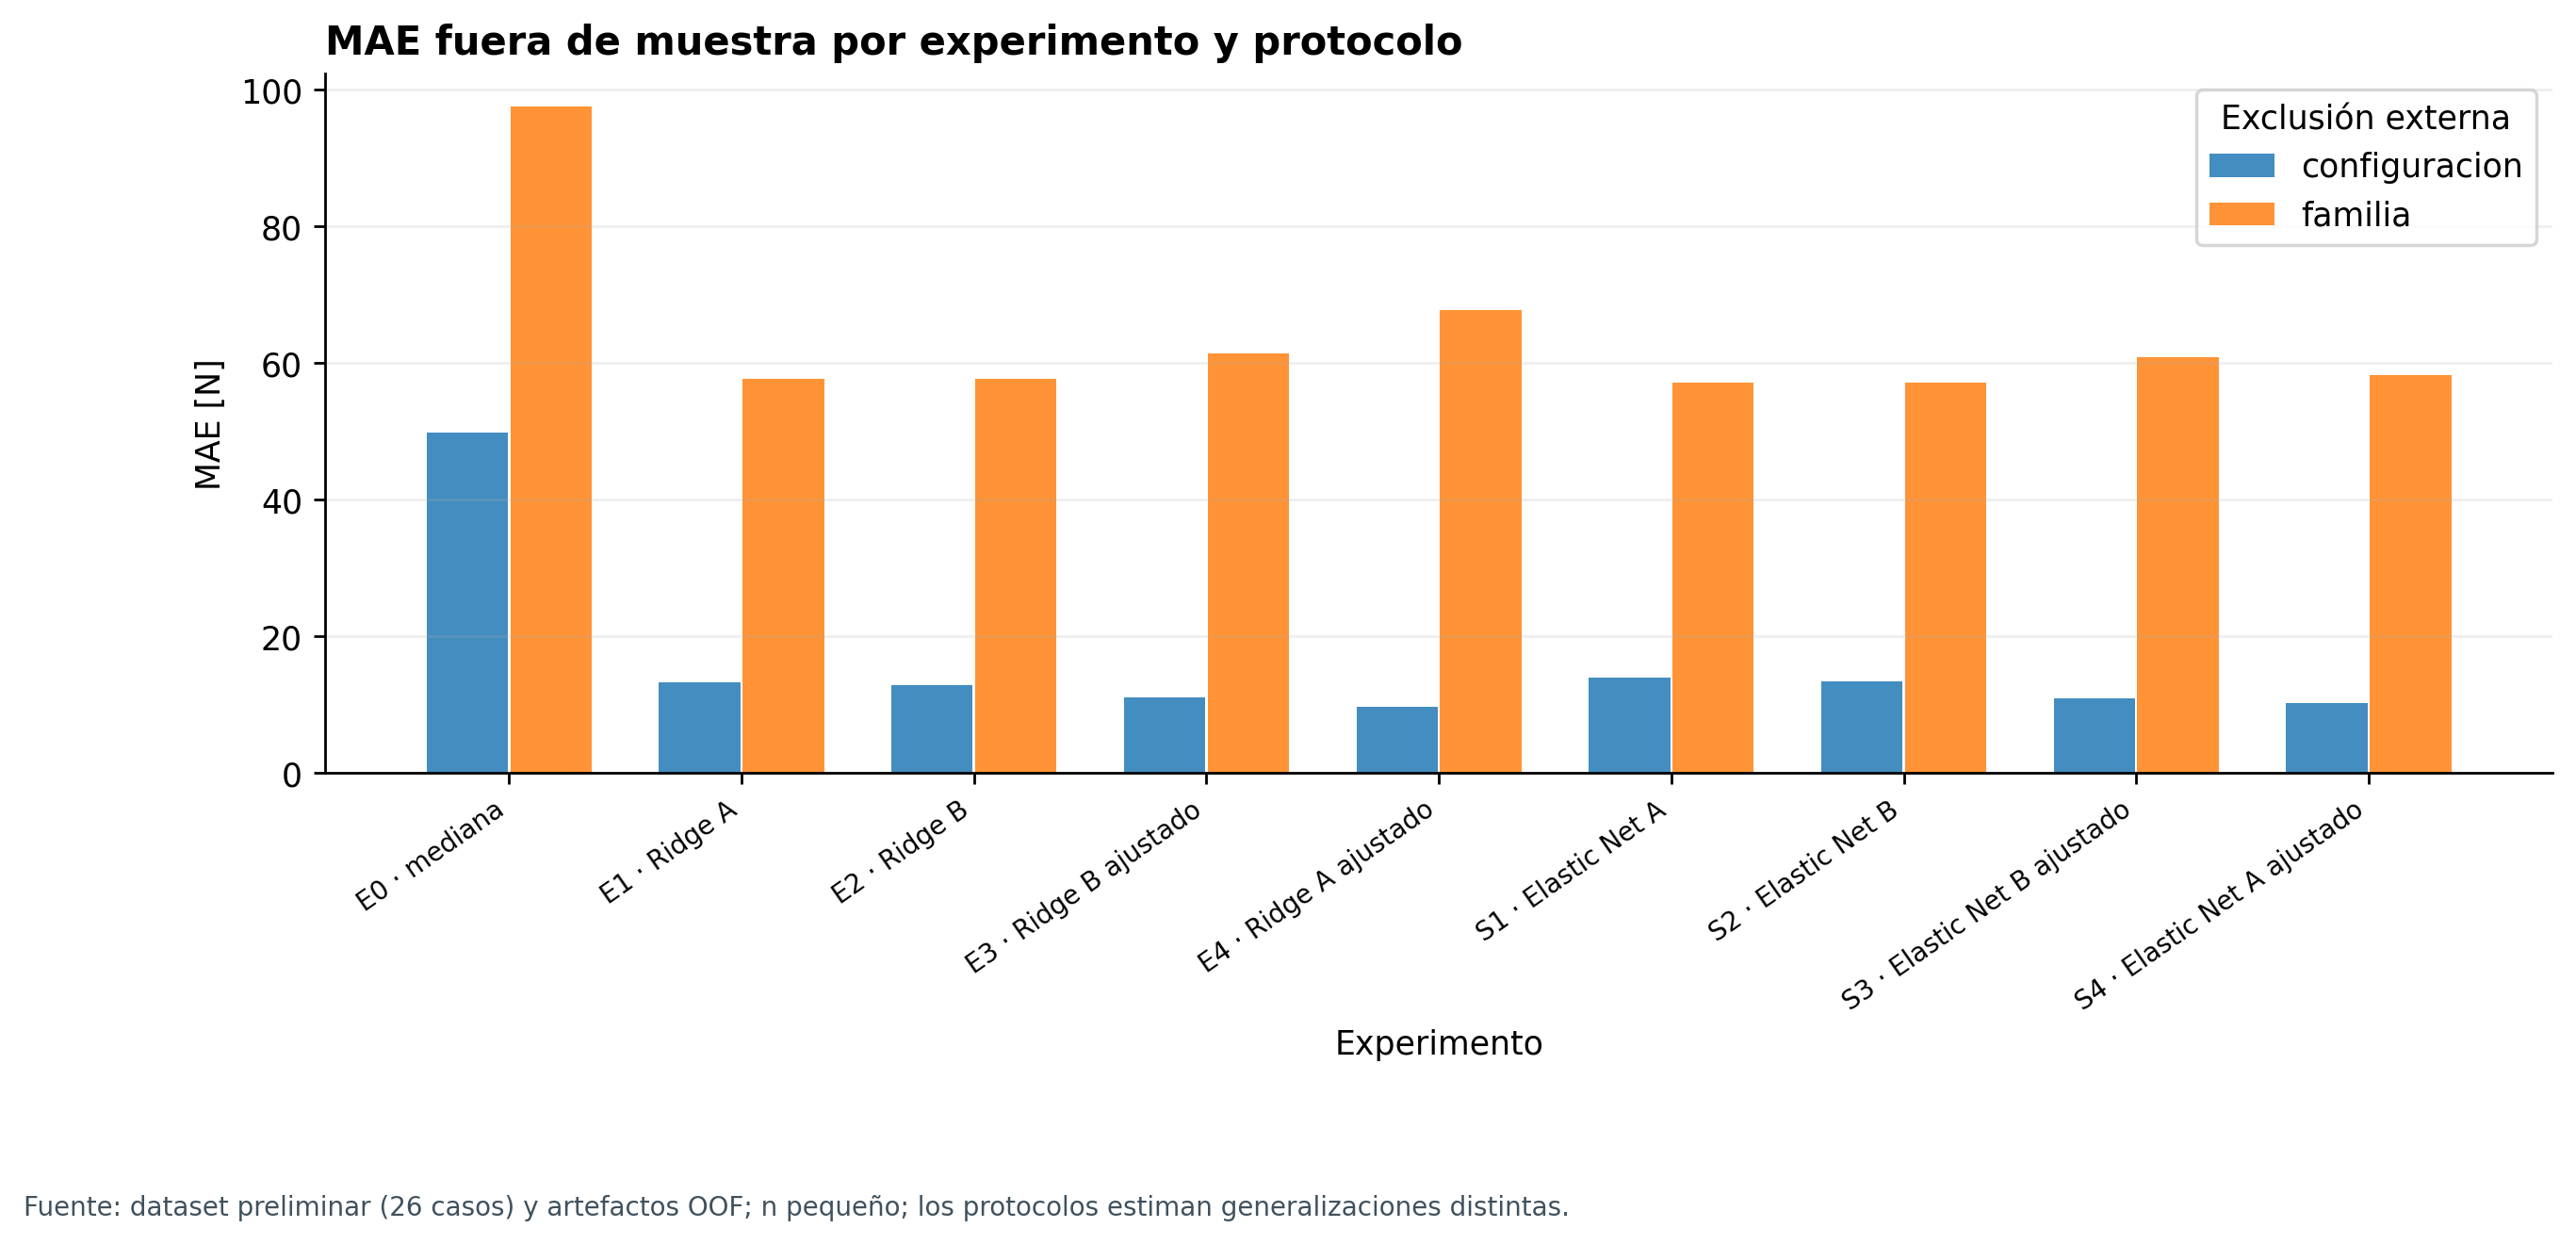

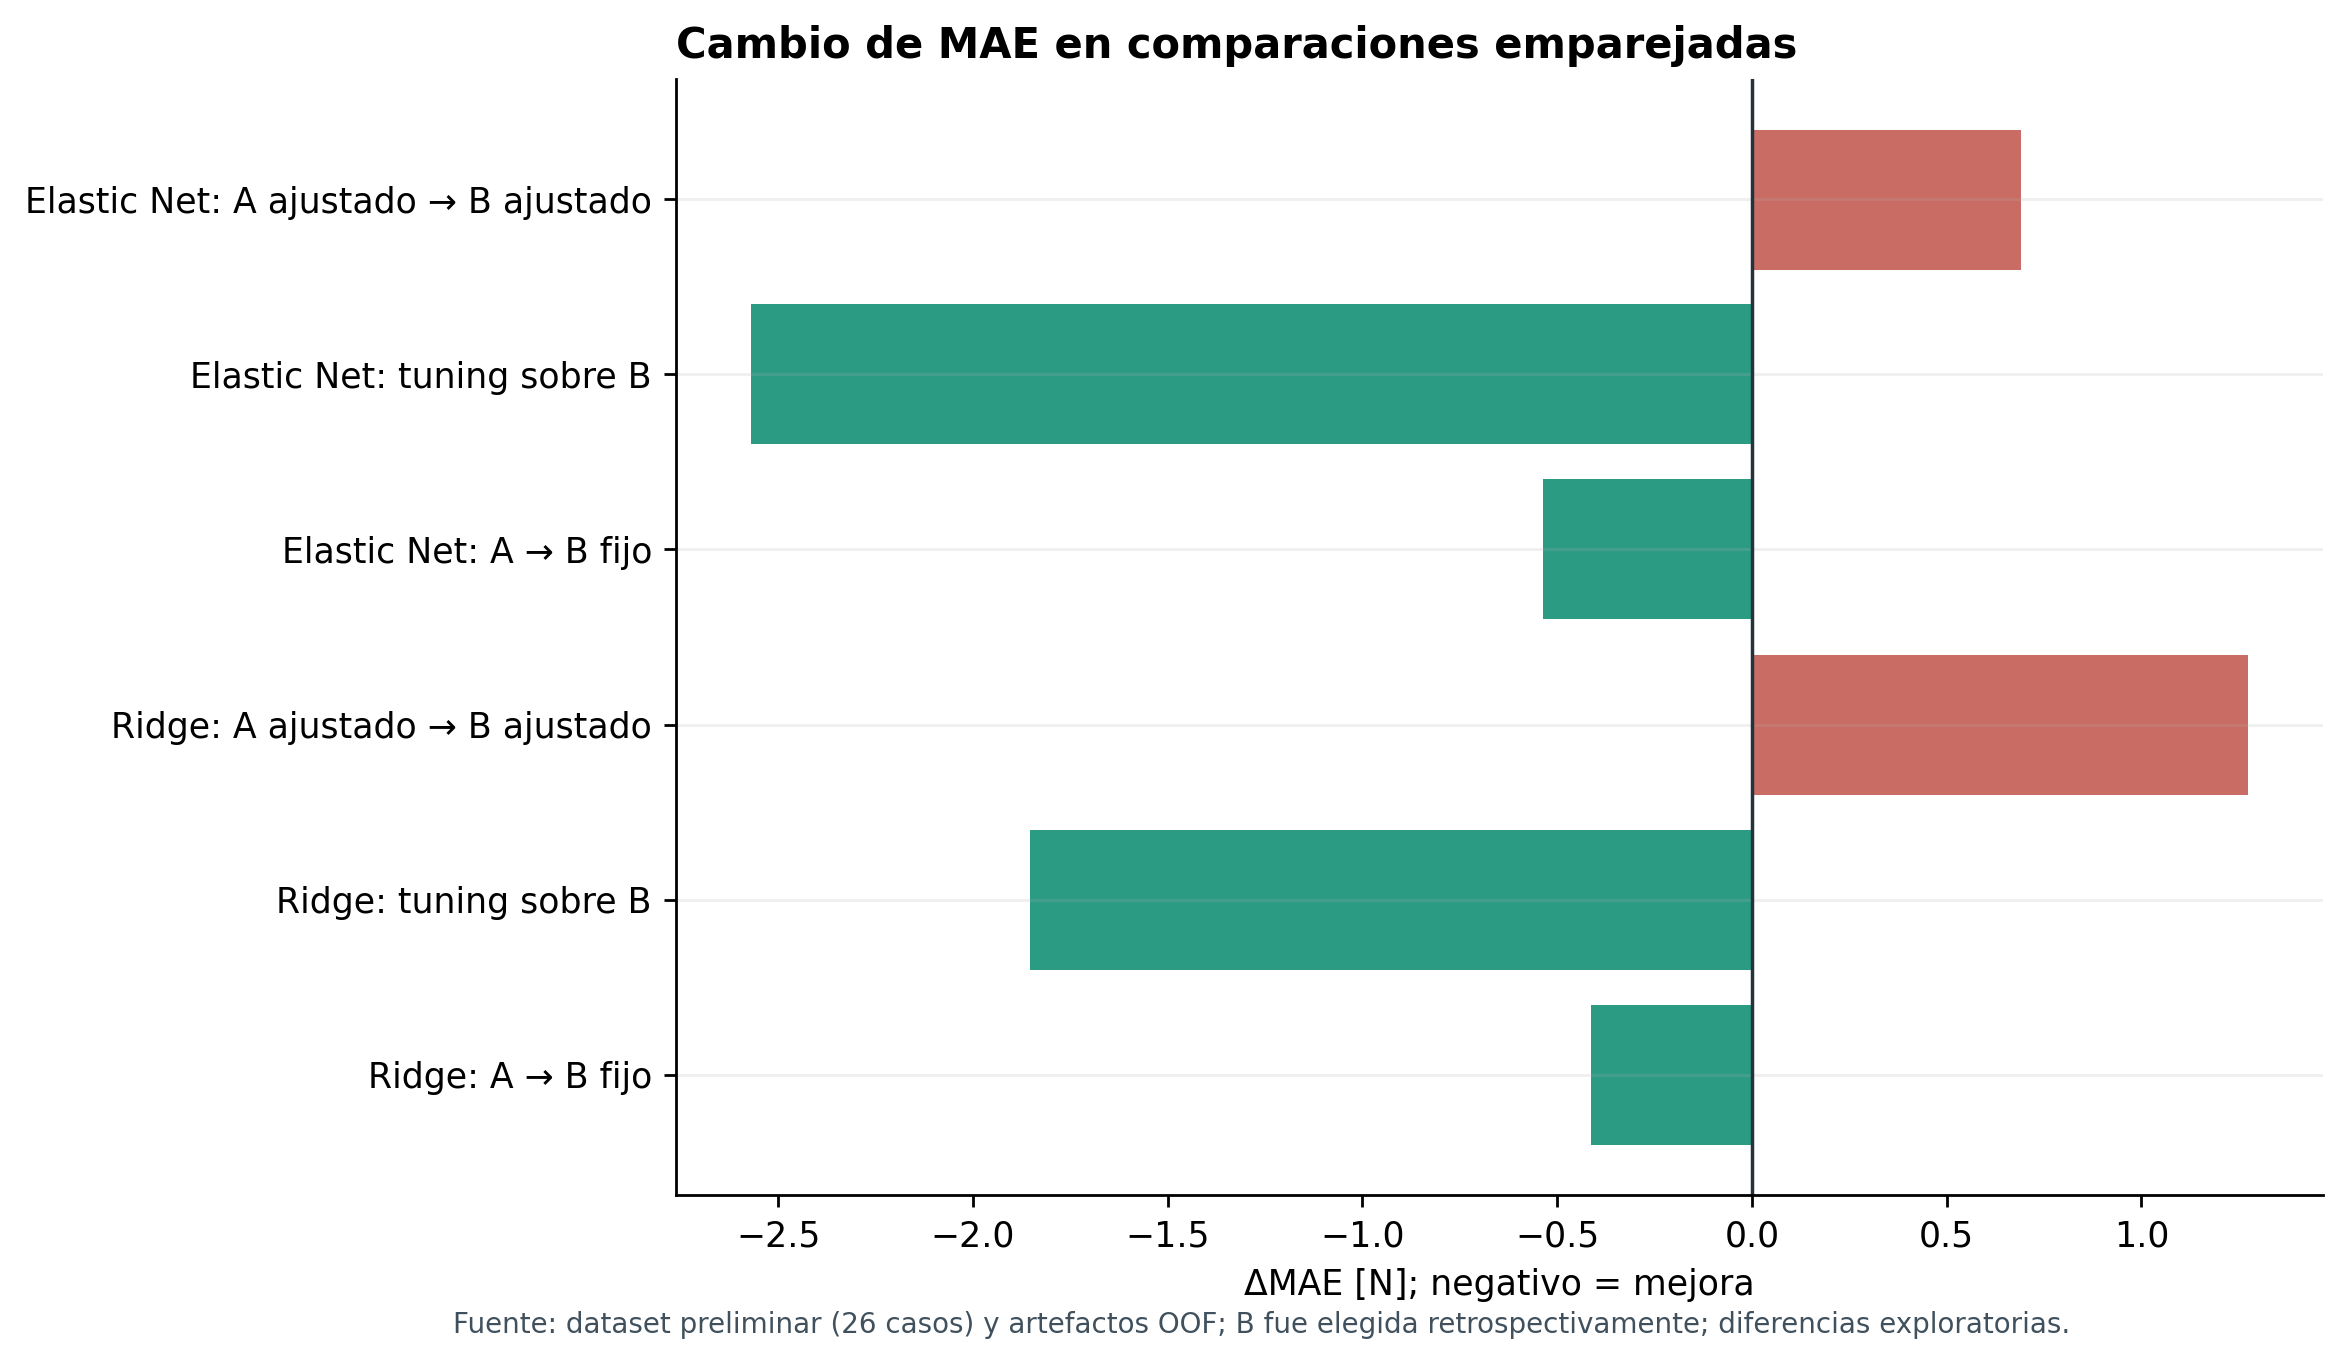

In [8]:
pareadas = tabla("comparacion_pareada")
display(pareadas[["protocolo", "referencia", "intervencion", "delta_MAE_N",
                  "fraccion_casos_mejora", "sd_delta_error_absoluto_N"]]
        .rename(columns={"protocolo":"Validación", "referencia":"Desde", "intervencion":"Hacia",
                         "delta_MAE_N":"ΔMAE [N]", "fraccion_casos_mejora":"Fracción casos mejora",
                         "sd_delta_error_absoluto_N":"SD Δerror [N]"}).round(3))
figura(1)
figura(2)

**Interpretación numérica.** En configuración, E2−E1 = **−0,4119 N**: B mejora apenas 3,11 % con Ridge fijo. E3−E2 = **−1,8532 N**: el tuning sí reduce el error sobre B. Pero E3−E4 = **+1,2744 N**: con ambos ajustados, A gana. Elastic Net repite el patrón: S2−S1 = **−0,5375 N**, S3−S2 = **−2,5692 N**, y S3−S4 = **+0,6920 N**. El menor MAE por configuración es **Ridge E4, 9,7070 N**; el menor MedAE es S3, 8,1519 N, por lo que distintas métricas ordenan de forma diferente.

Al reservar una familia Y completa, todos los R² OOF son **negativos**. El menor MAE es Elastic Net S2 fijo (**57,0958 N**), solo **0,0172 N** menor que S1; no se considera una mejora robusta. El tuning que mejora configuraciones puede empeorar la extrapolación de familias. La selección retrospectiva de B sobre los mismos 26 casos limita toda inferencia prospectiva.

### Diagnóstico complementario de tamaño de muestra (diapositiva 10 del PPT)

La curva siguiente usa **Ridge A fijo y `GroupKFold(5)` por configuración**, con tamaños de entrenamiento [10, 15, 20]. Es un diagnóstico exploratorio de cómo cambia el MAE con más observaciones; no reemplaza los 24 folds externos ni se usa para elegir un modelo o hiperparámetro.

,Casos train,MAE train [N],MAE validación [N],SD validación [N]
0,10,9.806,19.557,6.721
1,15,10.878,19.187,6.657
2,20,10.108,14.410,5.648


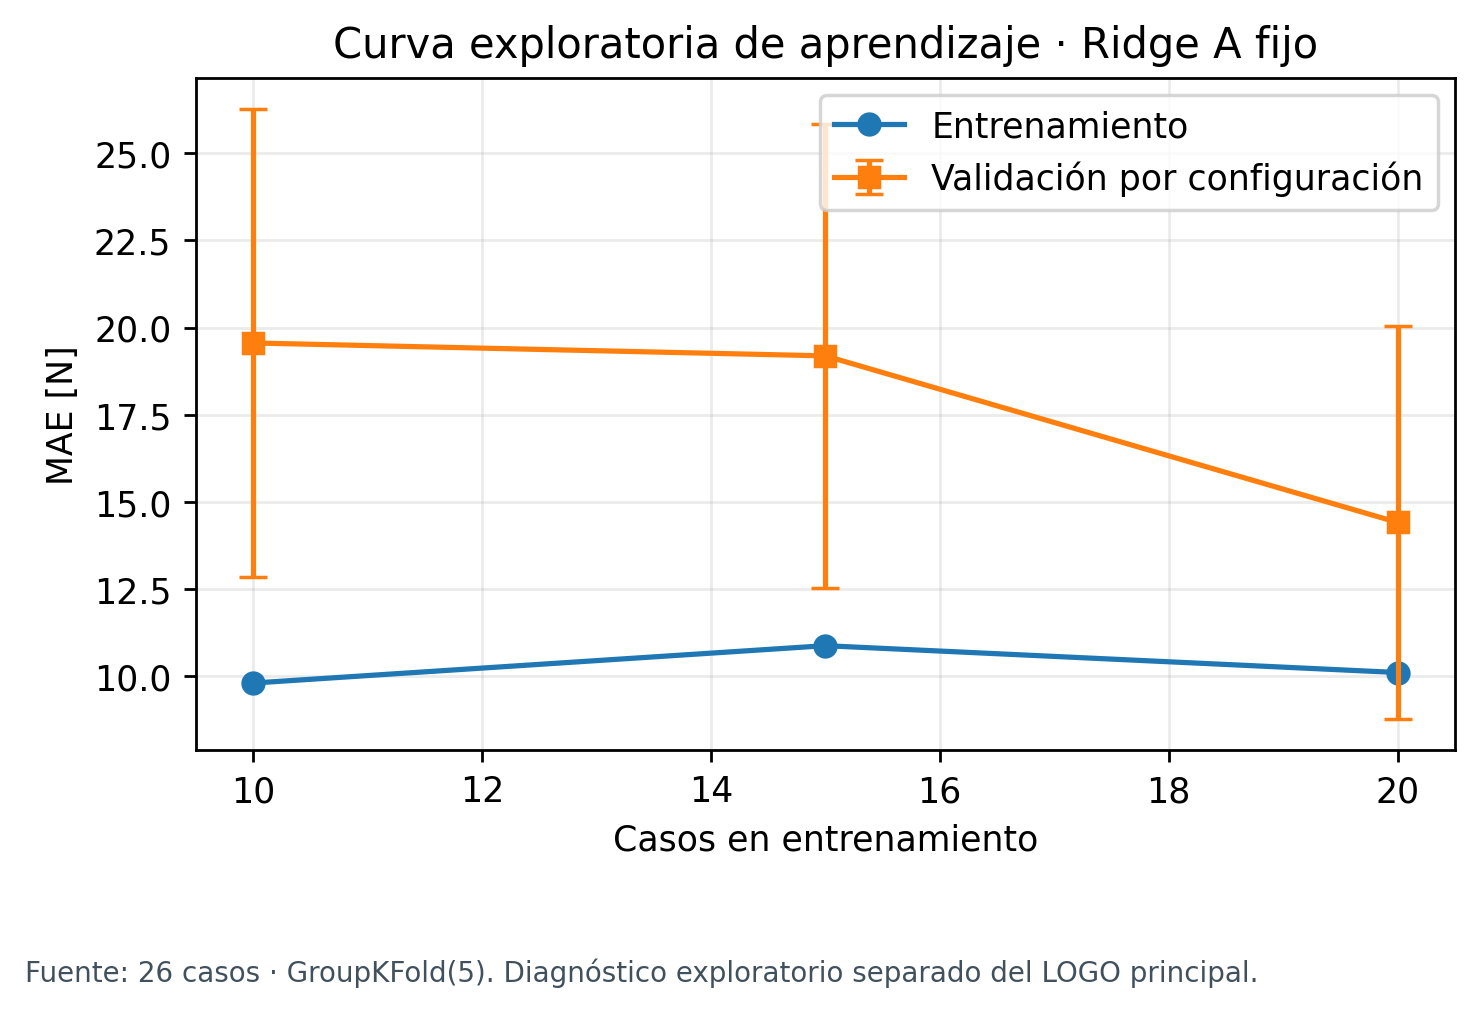

In [9]:
from sklearn.model_selection import GroupKFold, learning_curve
nominal = nominal_groups(frame, config["group_columns"])
sizes, train_scores, val_scores = learning_curve(
    make_pipeline("A"), X, y, groups=nominal, cv=GroupKFold(n_splits=5),
    train_sizes=[0.5, 0.75, 1.0], shuffle=True, random_state=42,
    scoring="neg_mean_absolute_error", n_jobs=1)
aprendizaje = pd.DataFrame({"Casos train": sizes, "MAE train [N]": -train_scores.mean(axis=1),
                           "MAE validación [N]": -val_scores.mean(axis=1),
                           "SD validación [N]": val_scores.std(axis=1, ddof=1)})
display(aprendizaje.round(3))
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(sizes, -train_scores.mean(axis=1), marker="o", label="Entrenamiento")
ax.errorbar(sizes, -val_scores.mean(axis=1), yerr=val_scores.std(axis=1, ddof=1),
            marker="s", capsize=4, label="Validación por configuración")
ax.set(title="Curva exploratoria de aprendizaje · Ridge A fijo",
       xlabel="Casos en entrenamiento", ylabel="MAE [N]")
ax.grid(alpha=0.25); ax.legend(loc="upper right")
fig.text(0.02, 0.02, "Fuente: 26 casos · GroupKFold(5). Diagnóstico exploratorio separado del LOGO principal.",
         fontsize=8, color="#40515d")
fig.subplots_adjust(bottom=0.24)
fig.savefig(FIGURES / "17_curva_aprendizaje.png", dpi=250, bbox_inches="tight", facecolor="white")
fig.savefig(FIGURES / "17_curva_aprendizaje.svg", bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=str(FIGURES / "17_curva_aprendizaje.png"), width=850))

La validación media baja de aproximadamente **19,56 N** (10 casos train) a **14,41 N** (20), con desviación entre folds todavía cercana a **5 N**. Es compatible con beneficio potencial de más ensayos, pero no extrapola una ley de aprendizaje ni estima cuántas observaciones bastan; los grupos disponibles siguen siendo escasos.

## 5 · Residuales y errores grandes

El error residual se define **observado − estimado**, en N. Las figuras 03–04 muestran E3 (Ridge con B ajustado), candidato FE bajo examen. Para el menor MAE E4 se calculan también sus propios residuales en la tabla; una predicción globalmente buena puede fallar en casos concretos.

,MAE_N,max_error_N,sesgo_observado_menos_predicho_N,SD_residuo_N
experimento,,,,
E3,10.981,42.297,0.168,14.682
E4,9.707,30.280,0.307,12.571
S3,10.872,42.250,-0.295,14.443
S4,10.180,30.254,0.266,12.875


,Case_n,Familia Y,Observado [N],Predicho [N],Residual [N],Error abs. [N]
49,1,4,47.55,77.83,-30.28,30.28
58,4,4,86.45,61.72,24.73,24.73
94,17,5,75.71,97.55,-21.84,21.84
22,3,4,88.50,69.19,19.31,19.31
130,10,5,114.30,97.02,17.28,17.28


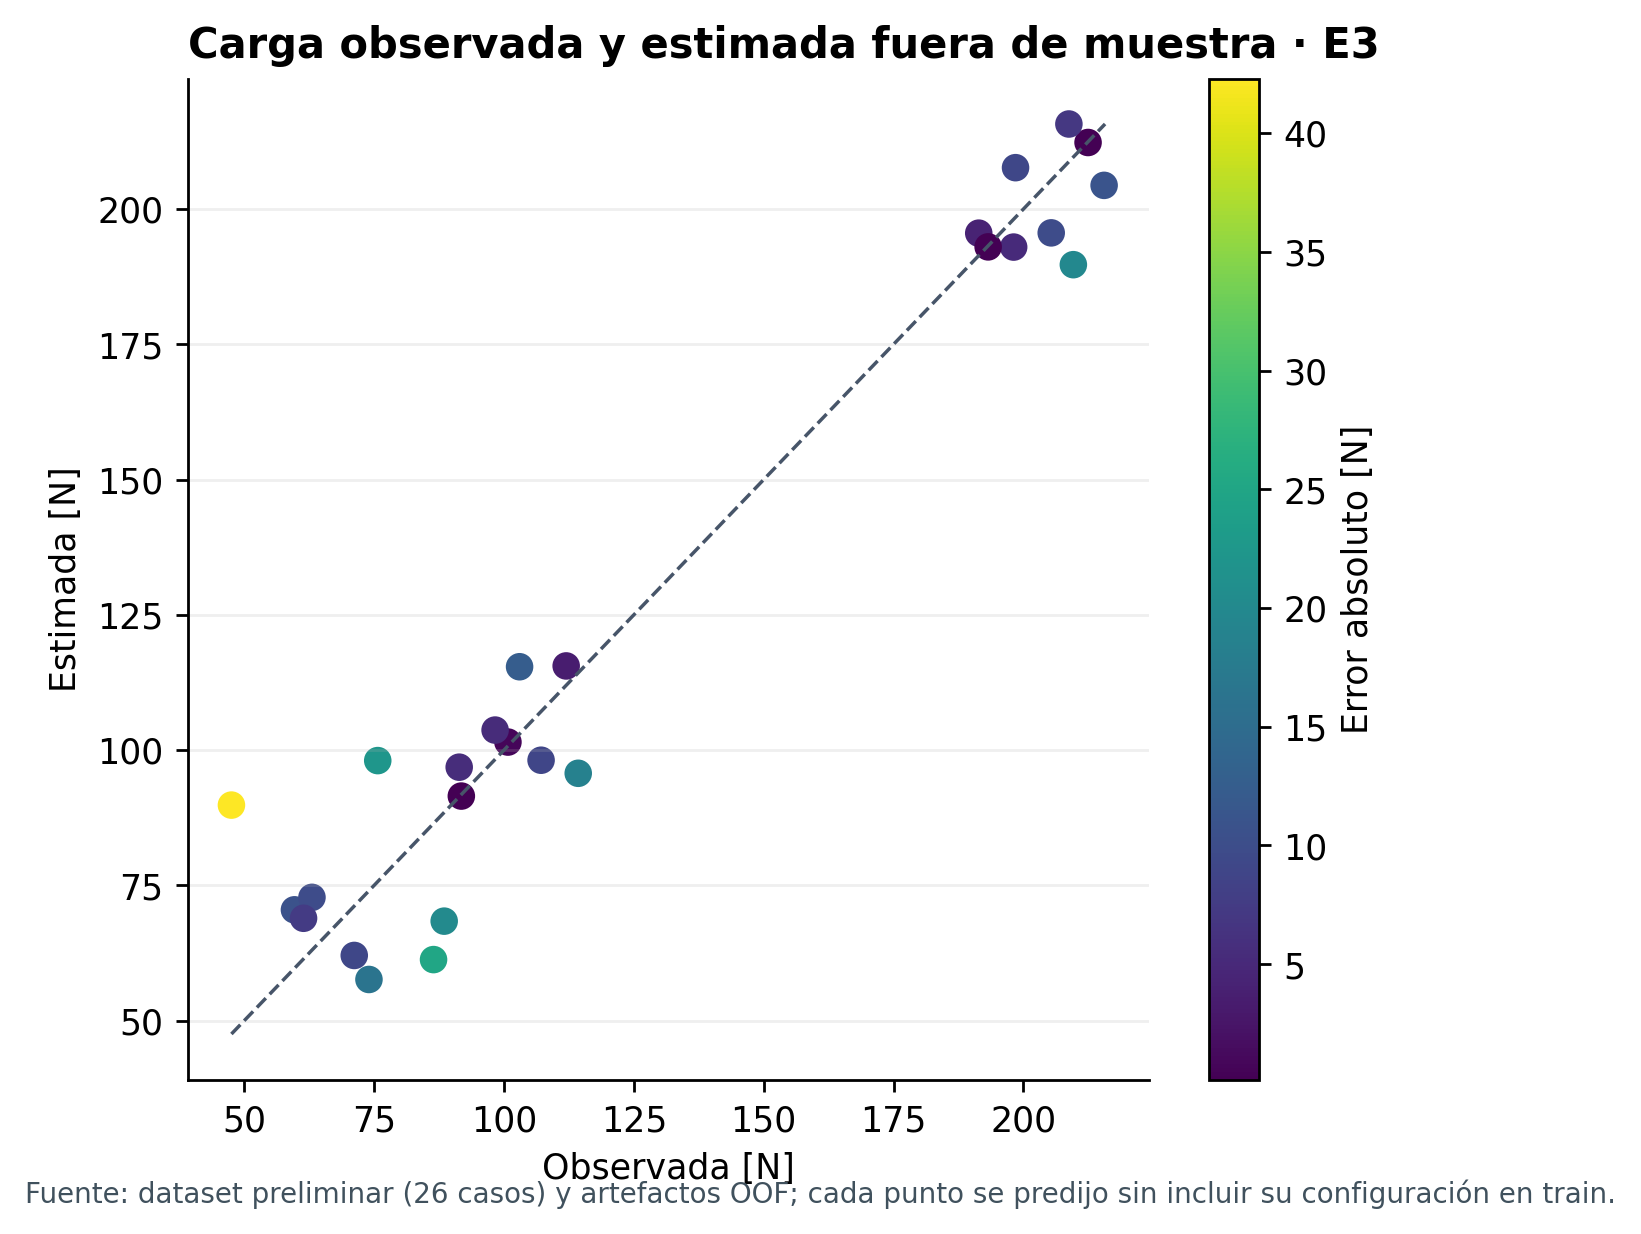

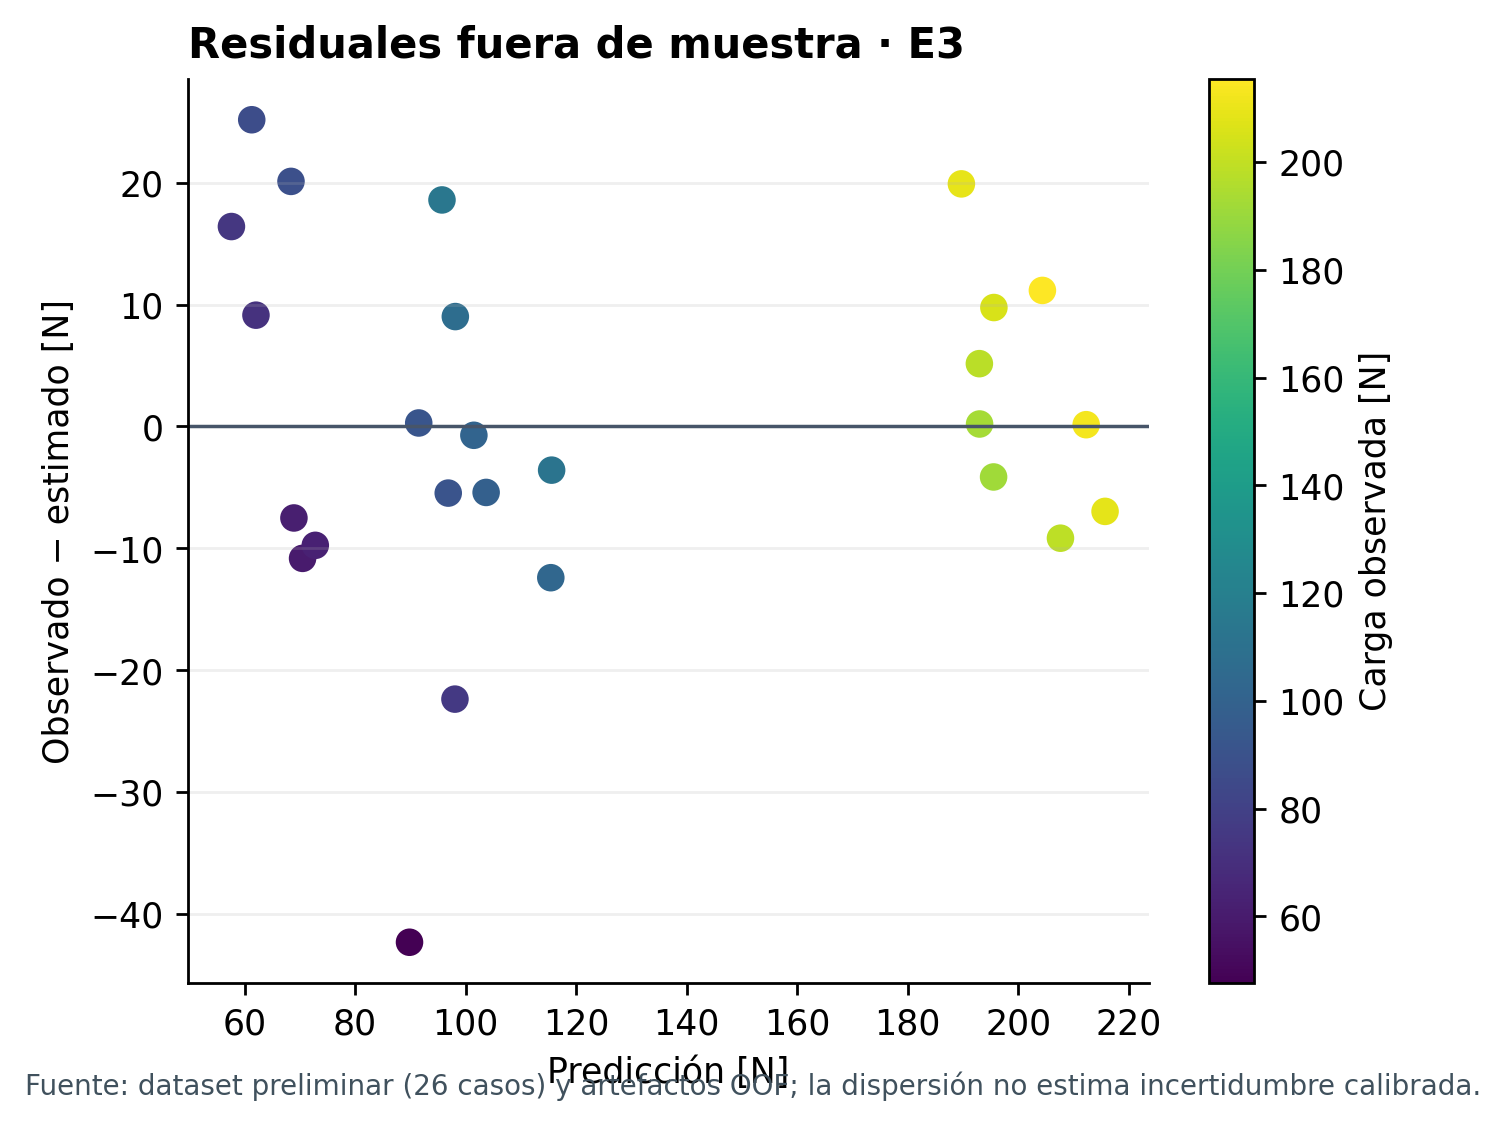

In [10]:
diag = pred[pred.protocolo.eq("configuracion") & pred.experimento.isin(["E3", "E4", "S3", "S4"])].copy()
diag["error_abs_N"] = (diag.observado_N - diag.predicho_N).abs()
display(diag.groupby("experimento").agg(MAE_N=("error_abs_N", "mean"),
                                         max_error_N=("error_abs_N", "max"),
                                         sesgo_observado_menos_predicho_N=("residuo_N", "mean"),
                                         SD_residuo_N=("residuo_N", "std")).round(3))
display(diag[diag.experimento.eq("E4")].nlargest(5, "error_abs_N")
        [["Case_n", "familia", "observado_N", "predicho_N", "residuo_N", "error_abs_N"]]
        .rename(columns={"familia":"Familia Y", "observado_N":"Observado [N]",
                         "predicho_N":"Predicho [N]", "residuo_N":"Residual [N]",
                         "error_abs_N":"Error abs. [N]"}).round(2))
figura(3)
figura(4)

In [11]:
familia_error = (pred[pred.protocolo.eq("familia") & pred.experimento.isin(["E1", "E3", "E4", "S1", "S2", "S3", "S4"])]
                 .groupby(["experimento", "familia"])
                 .error_absoluto_N.agg(["count", "mean", "max"]).reset_index())
display(familia_error.pivot(index="familia", columns="experimento", values="mean")
        .rename_axis("Familia Y").round(2))

experimento,E1,E3,E4,S1,S2,S3,S4
Familia Y,,,,,,,
4,55.40,23.83,45.03,55.27,53.41,53.39,49.76
5,41.59,41.23,40.80,41.01,42.61,43.21,40.44
6,75.67,114.82,114.95,74.85,74.86,84.99,83.50


**Lectura.** El salto del MAE desde ≈10 N por configuración hasta ≈57–68 N para Ridge al reservar familias muestra una falla de transferencia entre arquitecturas. No se atribuye a un mecanismo de daño específico: puede reflejar extrapolación geométrica, colinealidad, pocos casos y discrepancias documentales. No se calibraron intervalos predictivos.

## 6 · SHAP: método ejecutado y verificación de aditividad

Se explican **casos externos** a cada fit mediante `shap.LinearExplainer` para Ridge y Elastic Net. El `masker.Independent` recibe solo las características **transformadas del entrenamiento externo**. Esta opción calcula atribuciones interventional bajo una perturbación que no conserva todas las correlaciones geométricas; se informa explícitamente porque los descriptores de arquitectura son casi redundantes. El target no se transforma: valor base, SHAP y predicción están en **N**. Los valores físicos originales se conservan aparte de la escala estandarizada.

La demostración siguiente reproduce el primer fold E3 y verifica que **valor base + suma SHAP = predicción**. Las explicaciones de todos los folds están en las tablas de la ejecución completa.

In [12]:
import shap
selected = busquedas[(busquedas.protocolo.eq("configuracion")) &
                     (busquedas.experimento.eq("E3")) &
                     (busquedas.fold.eq(1)) &
                     (busquedas.selected.astype(str).str.lower().eq("true"))].iloc[0]
alpha = json.loads(selected.params_json)["model__alpha"]
modelo_explicado = make_pipeline("B", alpha=alpha).fit(X.iloc[train], y.iloc[train])
z_train = np.asarray(modelo_explicado[:-1].transform(X.iloc[train]), dtype=float)
z_test = np.asarray(modelo_explicado[:-1].transform(X.iloc[test]), dtype=float)
nombres = feature_names(modelo_explicado).tolist()
assert z_train.shape[1] == z_test.shape[1] == len(nombres)
explainer = shap.LinearExplainer(modelo_explicado.named_steps["model"],
                                shap.maskers.Independent(z_train, max_samples=len(train)))
explanation = explainer(z_test)
prediction = modelo_explicado.predict(X.iloc[test])
reconstructed = np.asarray(explanation.base_values).reshape(-1) + explanation.values.sum(axis=1)
assert np.allclose(reconstructed, prediction, atol=1e-6)
display(pd.DataFrame([{"Fold": 1, "Background train (casos)": len(train),
                       "Casos test": frame.iloc[test].Case_n.tolist(),
                       "Atributos alineados": len(nombres), "α interno": alpha,
                       "Predicción [N]": prediction.tolist(),
                       "Base + ΣSHAP [N]": reconstructed.tolist(),
                       "Desajuste máximo [N]": max(abs(reconstructed-prediction))}]))
display(pd.DataFrame({"Atributo": nombres, "Valor escalado": z_test[0],
                      "SHAP [N]": explanation.values[0]}).round(3))

,Fold,Background train (casos),Casos test,Atributos alineados,α interno,Predicción [N],Base + ΣSHAP [N],Desajuste máximo [N]
0,1,25,[5],11,0.0001,[70.49680097982099],[70.49680097982096],2.842171e-14


,Atributo,Valor escalado,SHAP [N]
0,n_cells_Y,-1.357,186.527
1,Fiber_height,0.000,-0.000
2,Fiber_base,0.765,-15.578
3,Fiber_total_length,-1.329,-55.952
4,Fiber_total_volume,1.190,8.612
5,Pivot_height,-0.049,-0.048
6,Pivot_total_number,-1.307,-240.108
7,Pivot_total_volume,-1.190,8.612
8,Sample_total_volume,-1.558,28.975
9,I_fibra_bh3_mm4,0.346,4.794


### Importancia global: leer primero el modelo con mejor MAE

`mean(|SHAP|)` resume cuánto se mueve la predicción por atributo **dentro de los modelos**. No representa un cambio causal de carga por modificar físicamente una variable. La tabla compara E4 (Ridge A, menor MAE), E3 (Ridge B) y S3 (Elastic Net B), con magnitud, variación entre folds y frecuencia de estar entre los tres primeros. La diferencia de escala entre E4 y E3 revela que mejor predicción no implica una atribución individual más estable.

In [13]:
shap_oof = tabla("shap_oof")
shap_global = tabla("shap_global")
global_top = (shap_global[shap_global.protocolo.eq("configuracion") &
                          shap_global.experimento.isin(["E4", "E3", "S3"])]
              .sort_values(["experimento", "rank_global"])
              .groupby("experimento").head(6))
global_top = global_top.assign(Variable=global_top.feature.map(lambda f: LABELS.get(f, f)))
display(global_top[["experimento", "Variable", "mean_abs_shap_N",
                    "sd_fold_mean_abs_shap_N", "top3_fold_fraction", "mean_signed_shap_N"]]
        .rename(columns={"experimento":"Modelo", "mean_abs_shap_N":"mean|SHAP| [N]",
                         "sd_fold_mean_abs_shap_N":"SD folds [N]",
                         "top3_fold_fraction":"Fracción top 3",
                         "mean_signed_shap_N":"Media con signo [N]"}).round(3))
recon = shap_oof.groupby(["protocolo", "experimento", "fold", "Case_n"], as_index=False).agg(
    base_N=("base_N", "first"), suma_shap_N=("shap_N", "sum"), predicho_N=("predicho_N", "first"))
assert (recon.base_N + recon.suma_shap_N - recon.predicho_N).abs().max() < 1e-5
display(pd.DataFrame([{"Explicaciones OOF": len(recon),
                       "Error máximo de reconstrucción [N]":
                       float((recon.base_N+recon.suma_shap_N-recon.predicho_N).abs().max())}]))

,Modelo,Variable,mean|SHAP| [N],SD folds [N],Fracción top 3,Media con signo [N]
27,E3,Número total de pivotes [conteo],102.889,92.734,0.708,20.255
30,E3,Número de celdas en Y [conteo],62.908,72.416,0.292,-20.540
22,E3,Longitud total de fibras [mm],34.039,23.175,0.583,1.100
29,E3,Volumen declarado del espécimen [mm³],23.678,14.227,0.458,0.324
25,E3,Momento de sección h·b³/12 [mm⁴],18.068,24.489,0.333,3.492
21,E3,Altura de sección de fibra [mm],16.986,13.940,0.250,-0.204
36,E4,Número total de pivotes [conteo],196.598,126.874,1.000,1.578
39,E4,Número de celdas en Y [conteo],153.697,110.880,1.000,-0.794
33,E4,Longitud total de fibras [mm],39.200,26.476,0.750,0.172
38,E4,Volumen declarado del espécimen [mm³],16.106,9.486,0.208,-0.318


,Explicaciones OOF,Error máximo de reconstrucción [N]
0,416,8.526513e-14


**Hallazgo.** En E4, `Pivot_total_number` alcanza **196,60 N** y `n_cells_Y` **153,70 N** de `mean(|SHAP|)`; sus SD entre folds son **126,87** y **110,88 N**. E4 predice mejor por configuración, pero usa una regularización α≈0,0001 en la mayoría de folds y reparte contribuciones muy grandes entre variables casi equivalentes. En E3, pivotes **102,89 N**, celdas Y **62,91 N** y longitud de fibras **34,04 N**. En S3, pivotes **66,31 N** y longitud **30,69 N**; el orden y las magnitudes cambian con la regularización. Ninguno de estos números equivale a fuerza causada por un pivote.

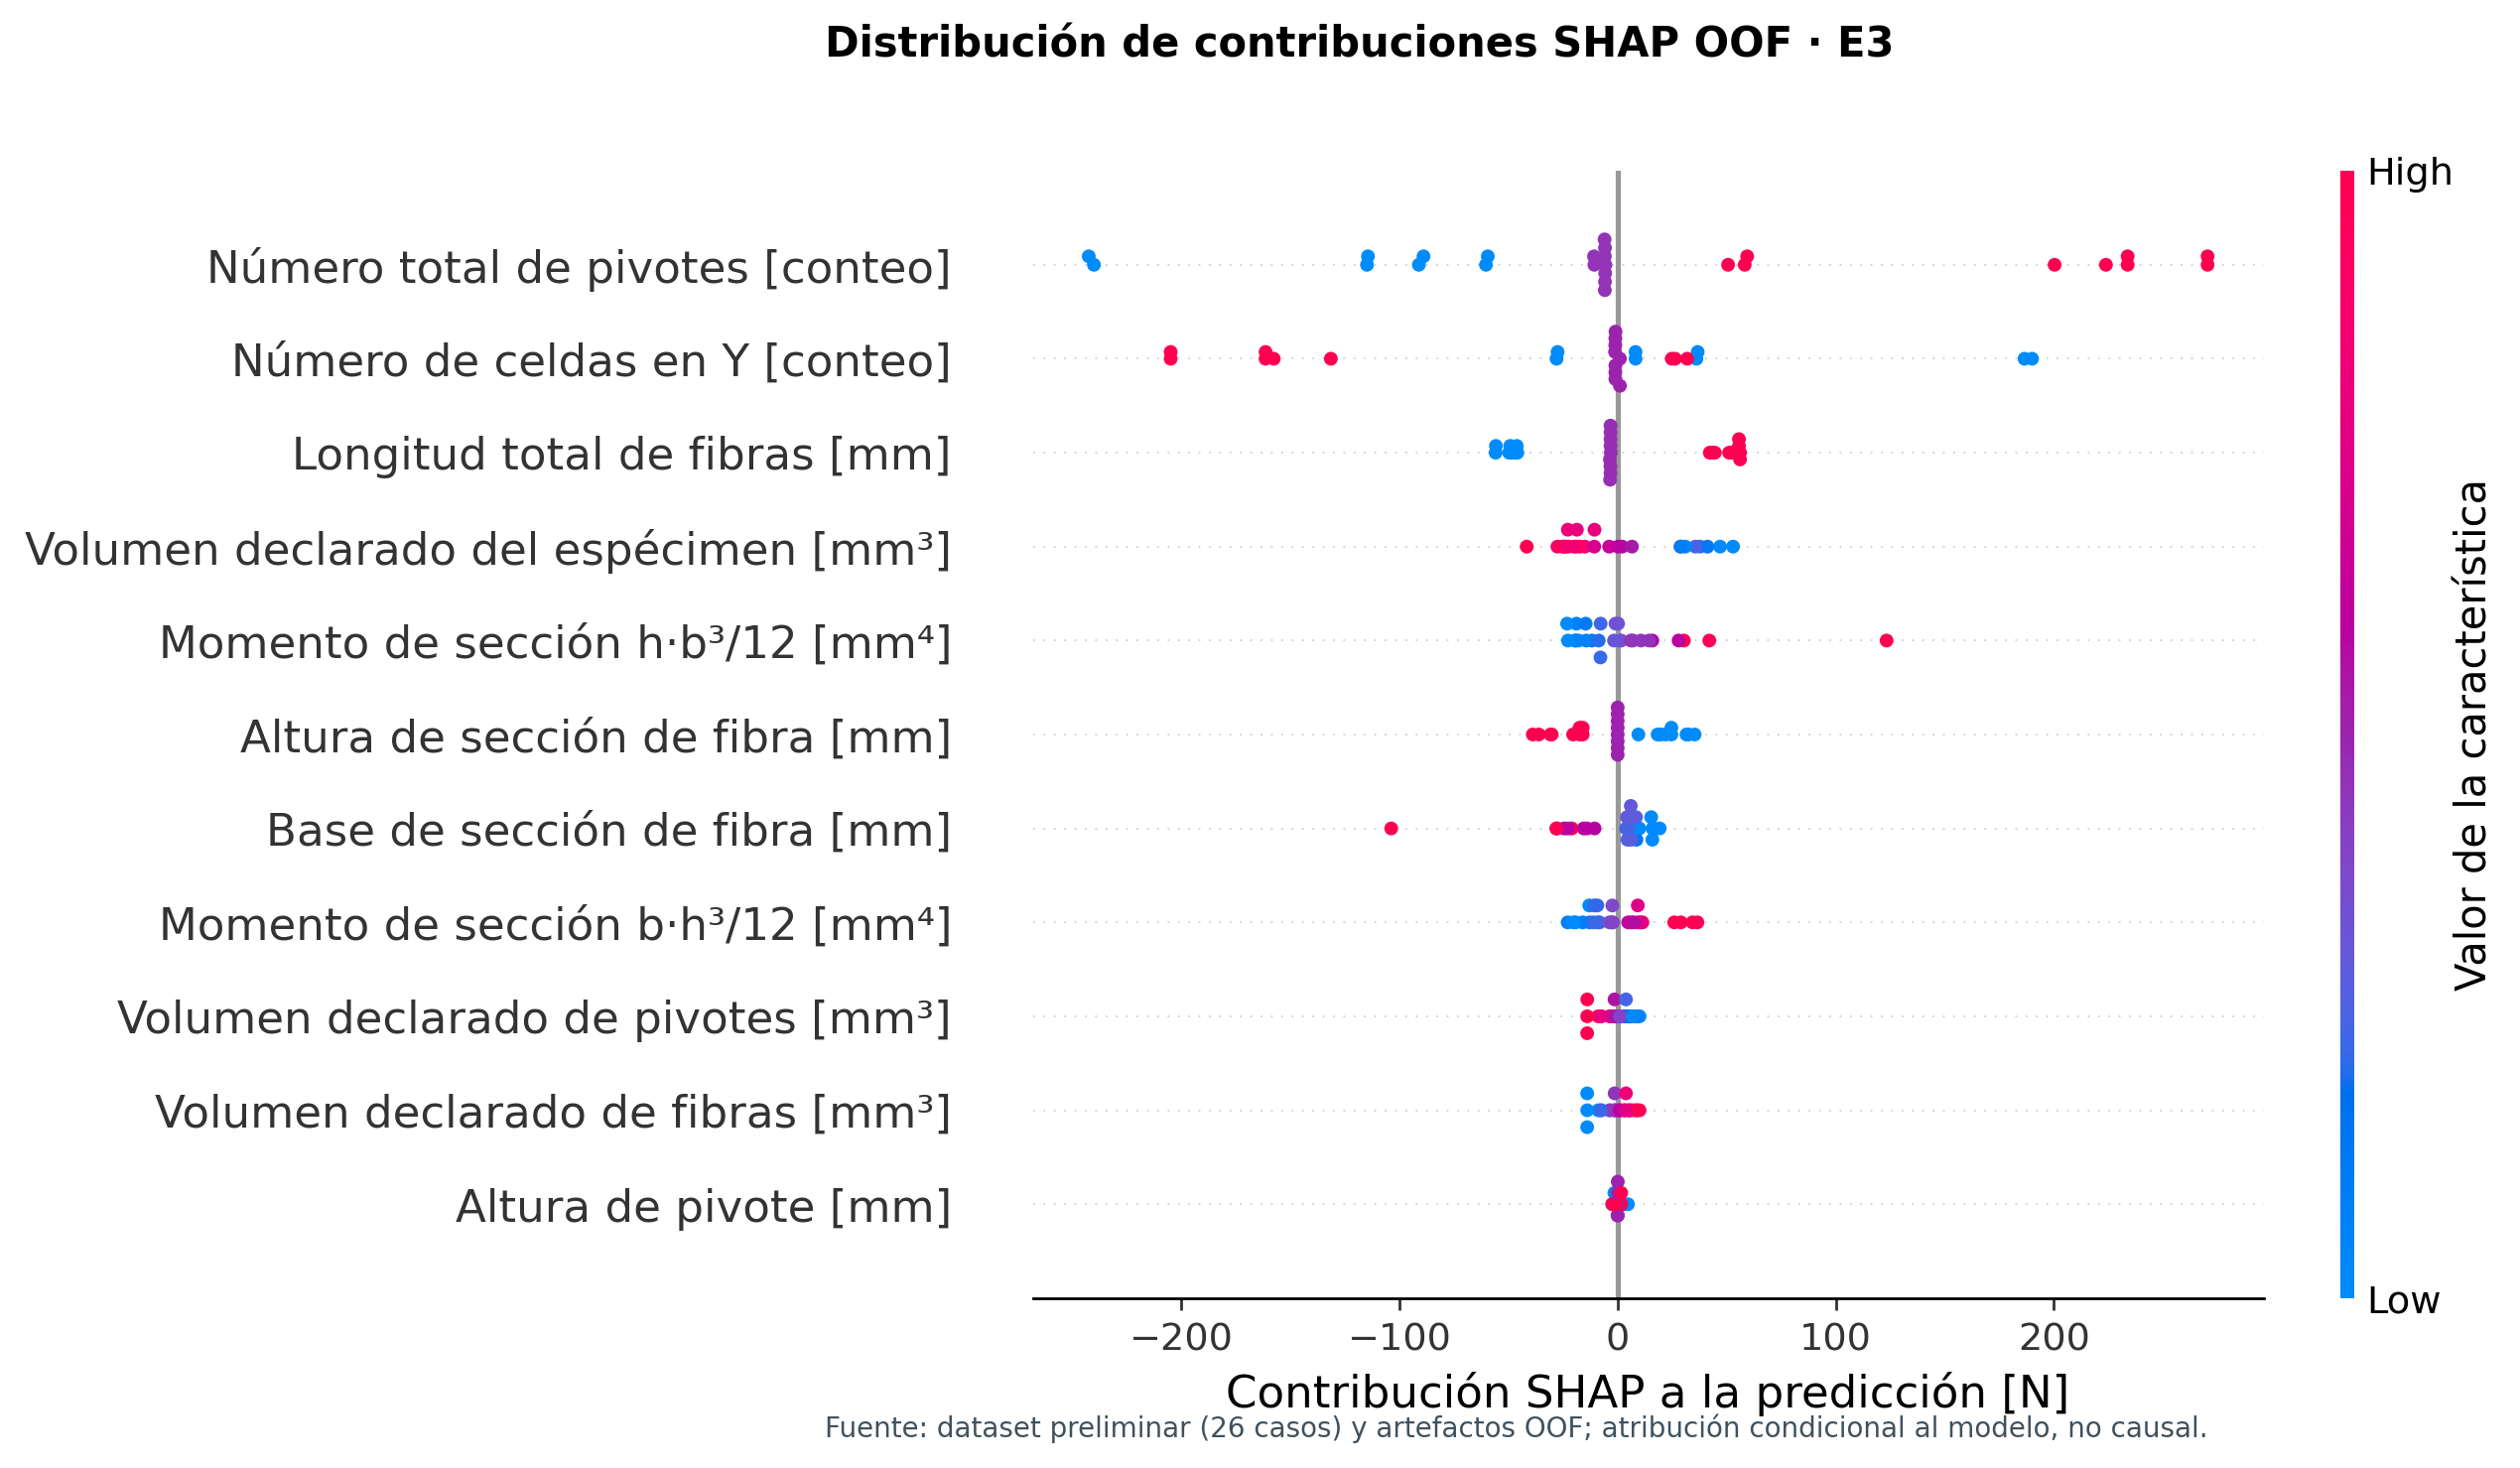

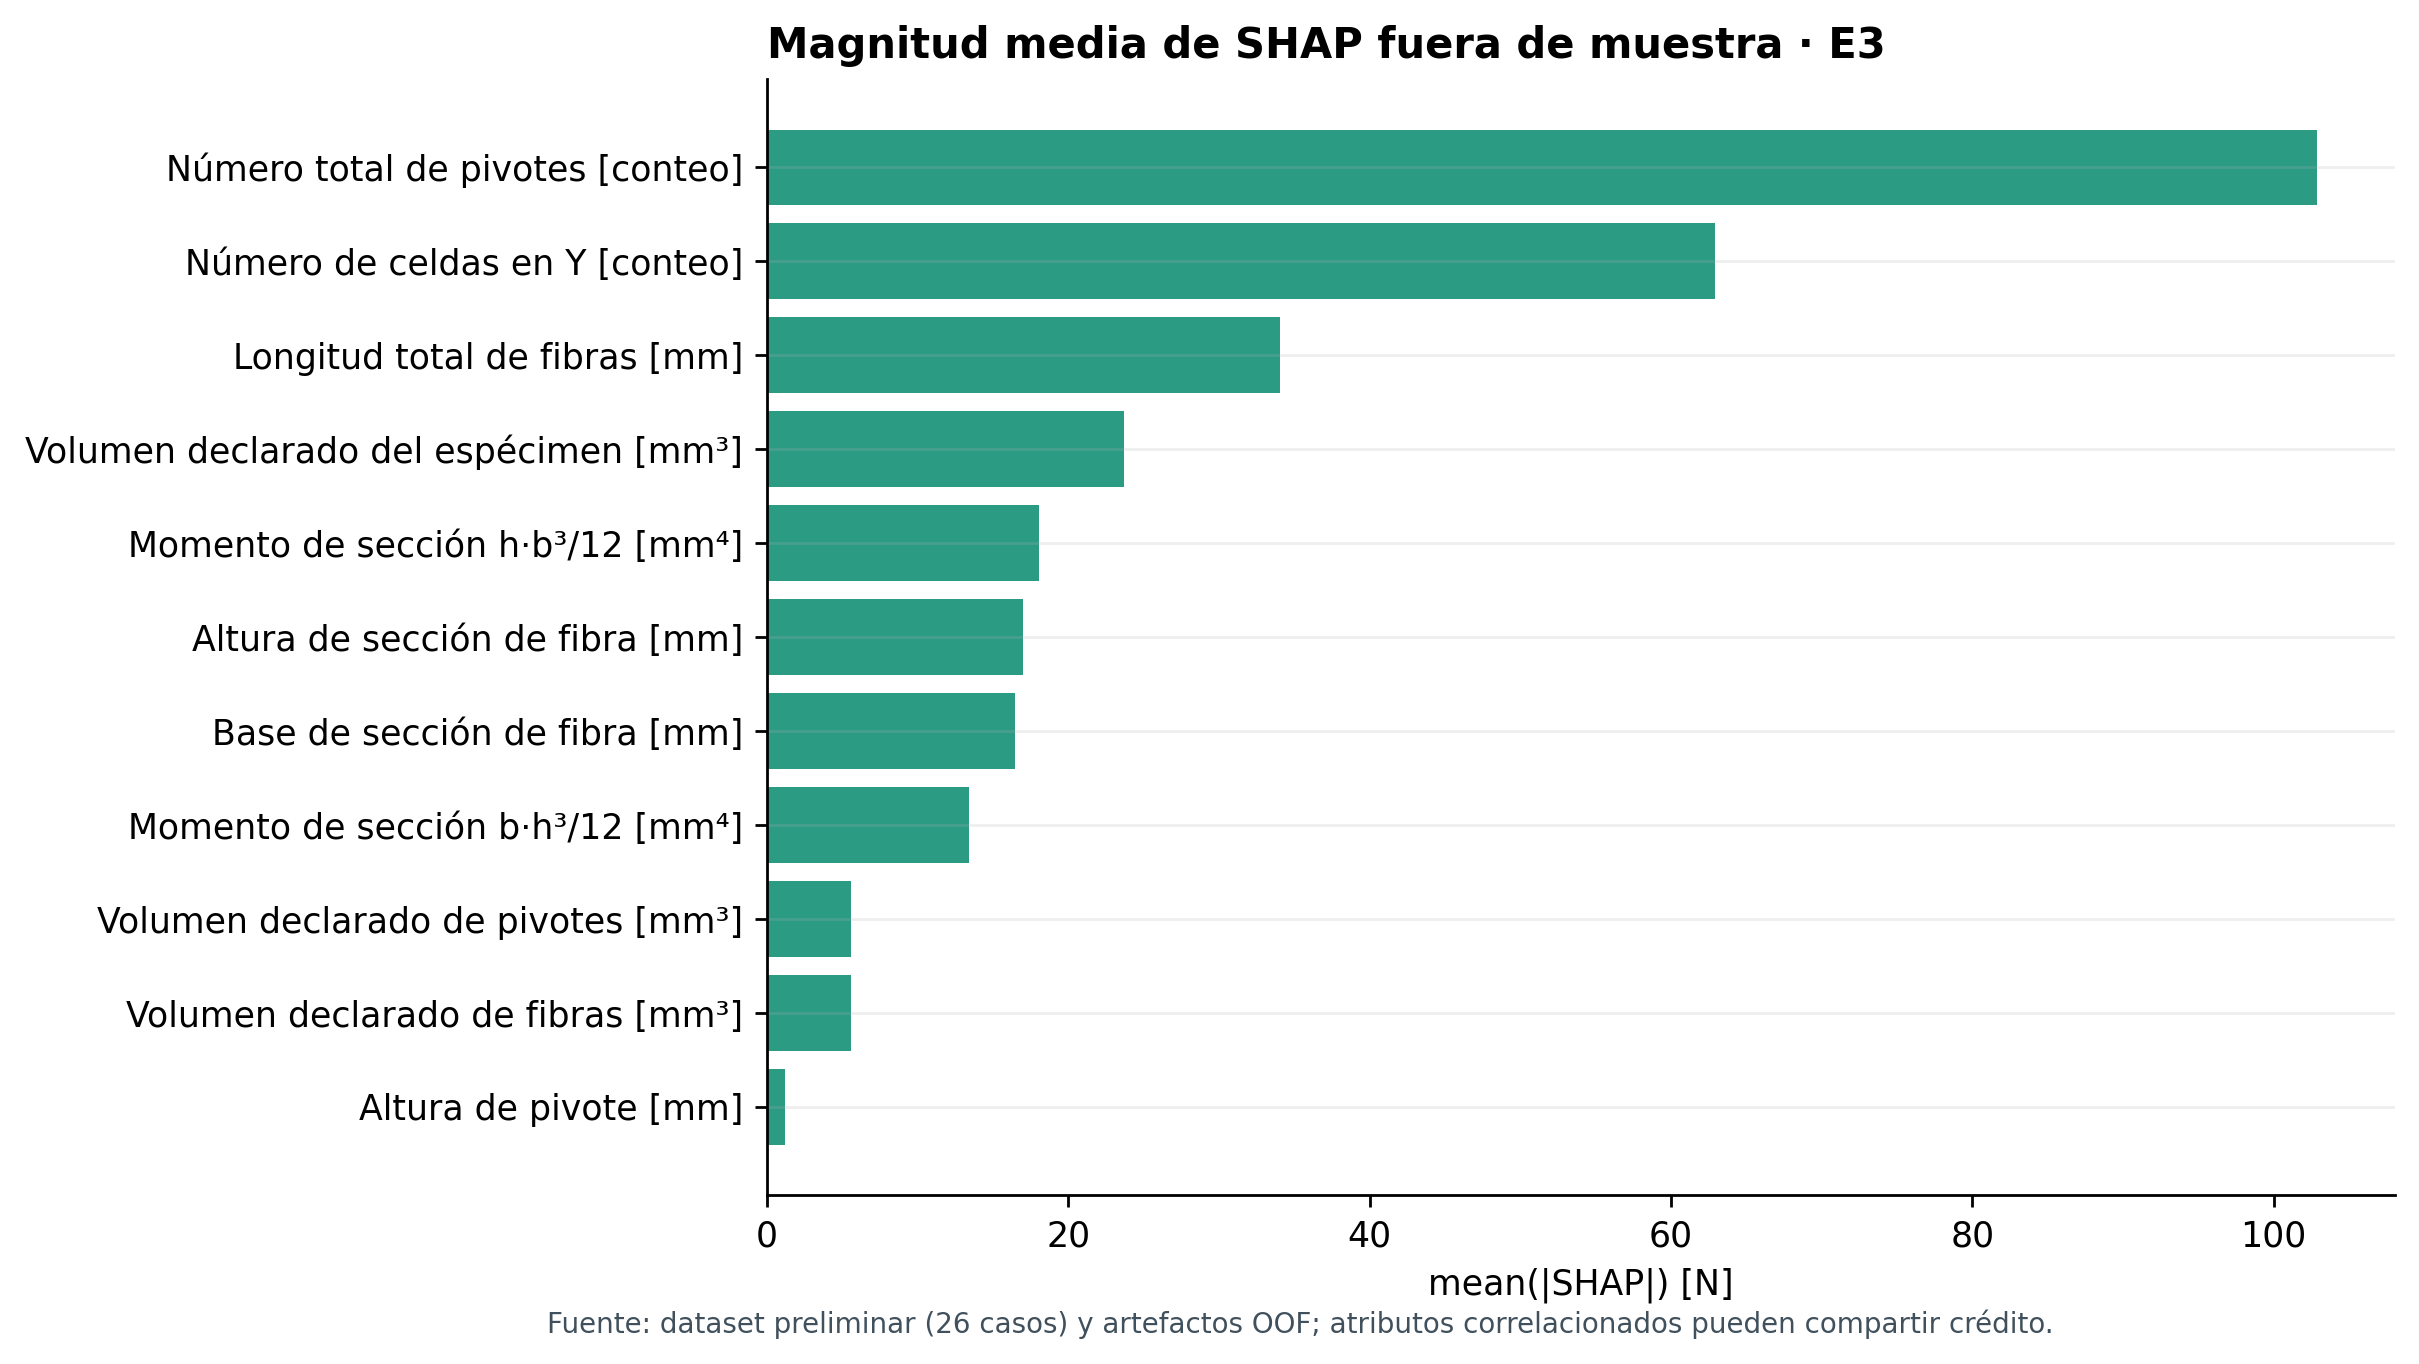

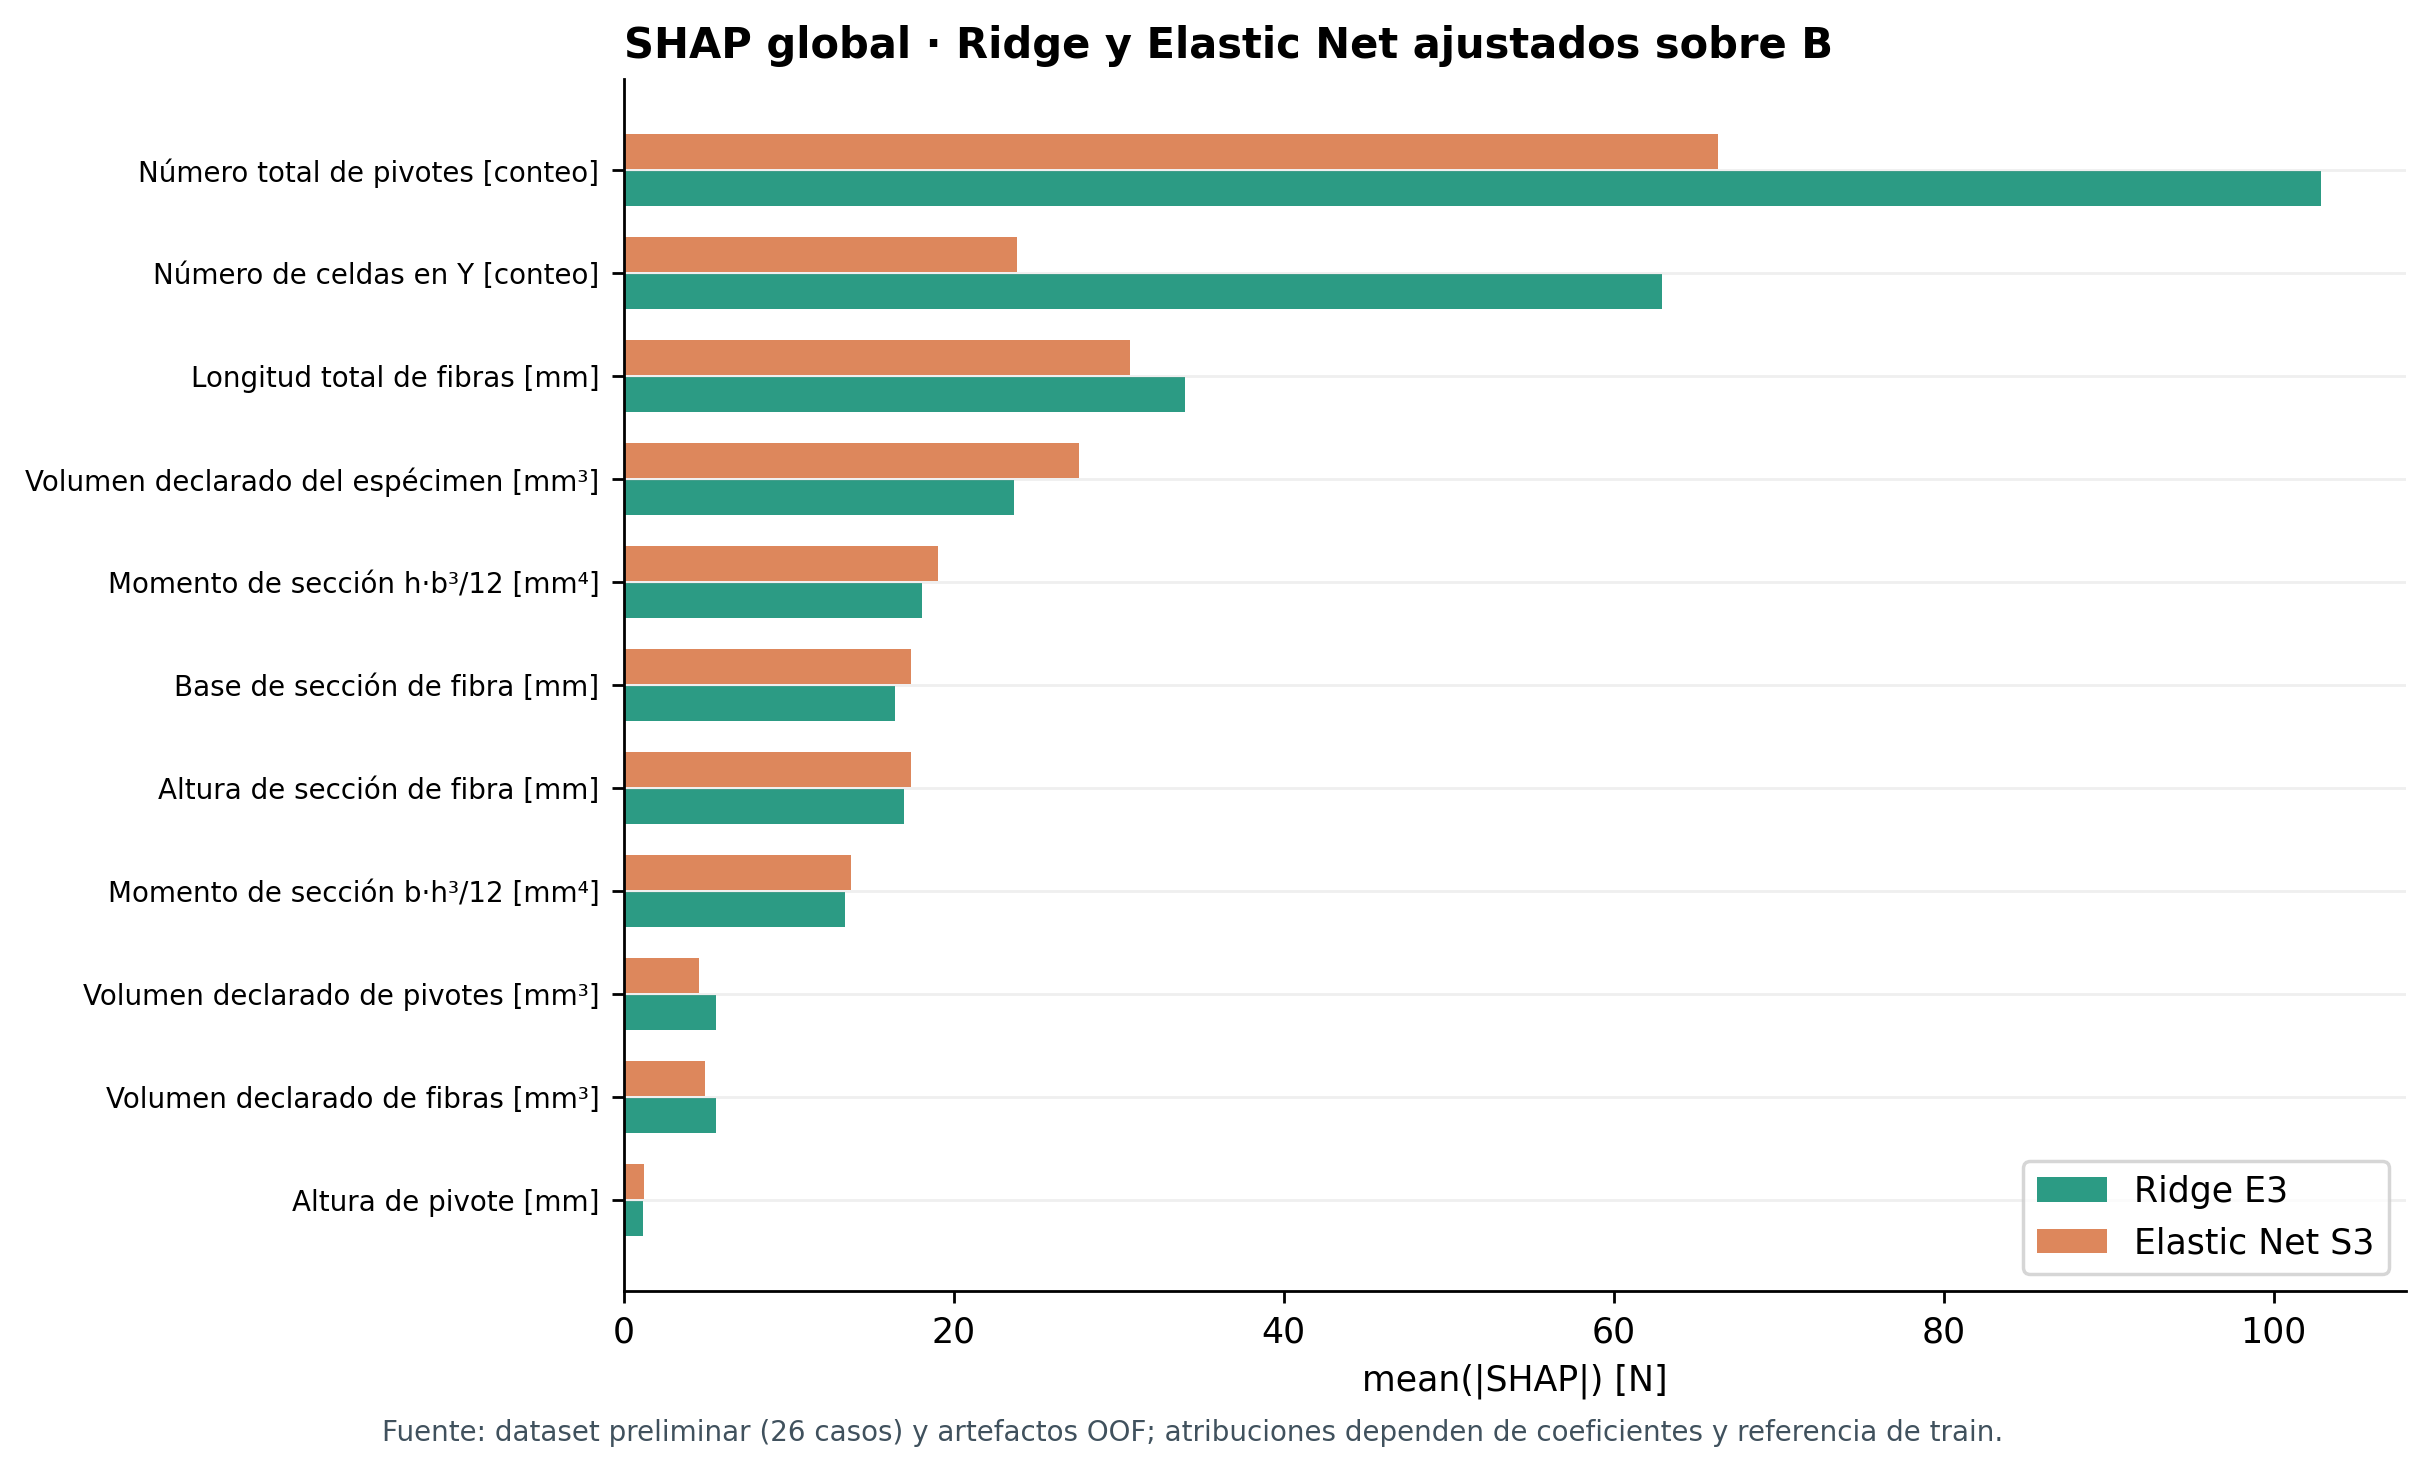

In [14]:
figura(5)  # beeswarm E3: distribución, signo y valor físico
figura(6)  # ranking E3
figura(10) # mismo B ajustado: Ridge frente a Elastic Net

### Estabilidad y dirección entre folds

El ranking global oculta cambios entre folds. En E3, el número de pivotes aparece en el top 3 en **70,8 %** de los 24 folds de configuración, pero su SD de magnitud es **92,73 N**; `n_cells_Y` aparece en el top 3 solo **29,2 %**. En E4 ambos encabezan los folds, con magnitudes todavía más variables. El signo local indica desviación respecto de la base de *ese fold*; para la dirección condicionada se inspeccionan también los coeficientes estandarizados, sin leerlos como efectos físicos aislados.

,Modelo,Variable,Coef. medio [N/z],SD coef. [N/z],Fracción signo +
2,E3,Fiber_total_length,37.149,2.793,1.000
4,E3,I_fibra_bh3_mm4,14.318,4.193,1.000
5,E3,I_fibra_hb3_mm4,22.606,7.955,1.000
7,E3,Pivot_total_number,87.432,55.962,1.000
10,E3,n_cells_Y,-26.427,64.592,0.500
13,E4,Fiber_total_length,44.531,1.127,1.000
16,E4,Pivot_total_number,222.371,14.557,1.000
19,E4,n_cells_Y,-180.354,16.409,0.000
22,S3,Fiber_total_length,35.268,1.522,1.000
24,S3,I_fibra_bh3_mm4,14.872,3.831,1.000


,Modelo,Variable,Fracción top 5,Rango mediano
7,E3,Pivot_total_number,0.875,1.0
10,E3,n_cells_Y,0.500,5.5
2,E3,Fiber_total_length,0.708,3.0
9,E3,Sample_total_volume,0.792,4.0
5,E3,I_fibra_hb3_mm4,0.750,5.0
16,E4,Pivot_total_number,1.000,1.0
19,E4,n_cells_Y,1.000,2.0
13,E4,Fiber_total_length,0.917,3.0
18,E4,Sample_total_volume,0.917,4.0
17,E4,Pivot_total_volume,0.625,5.0


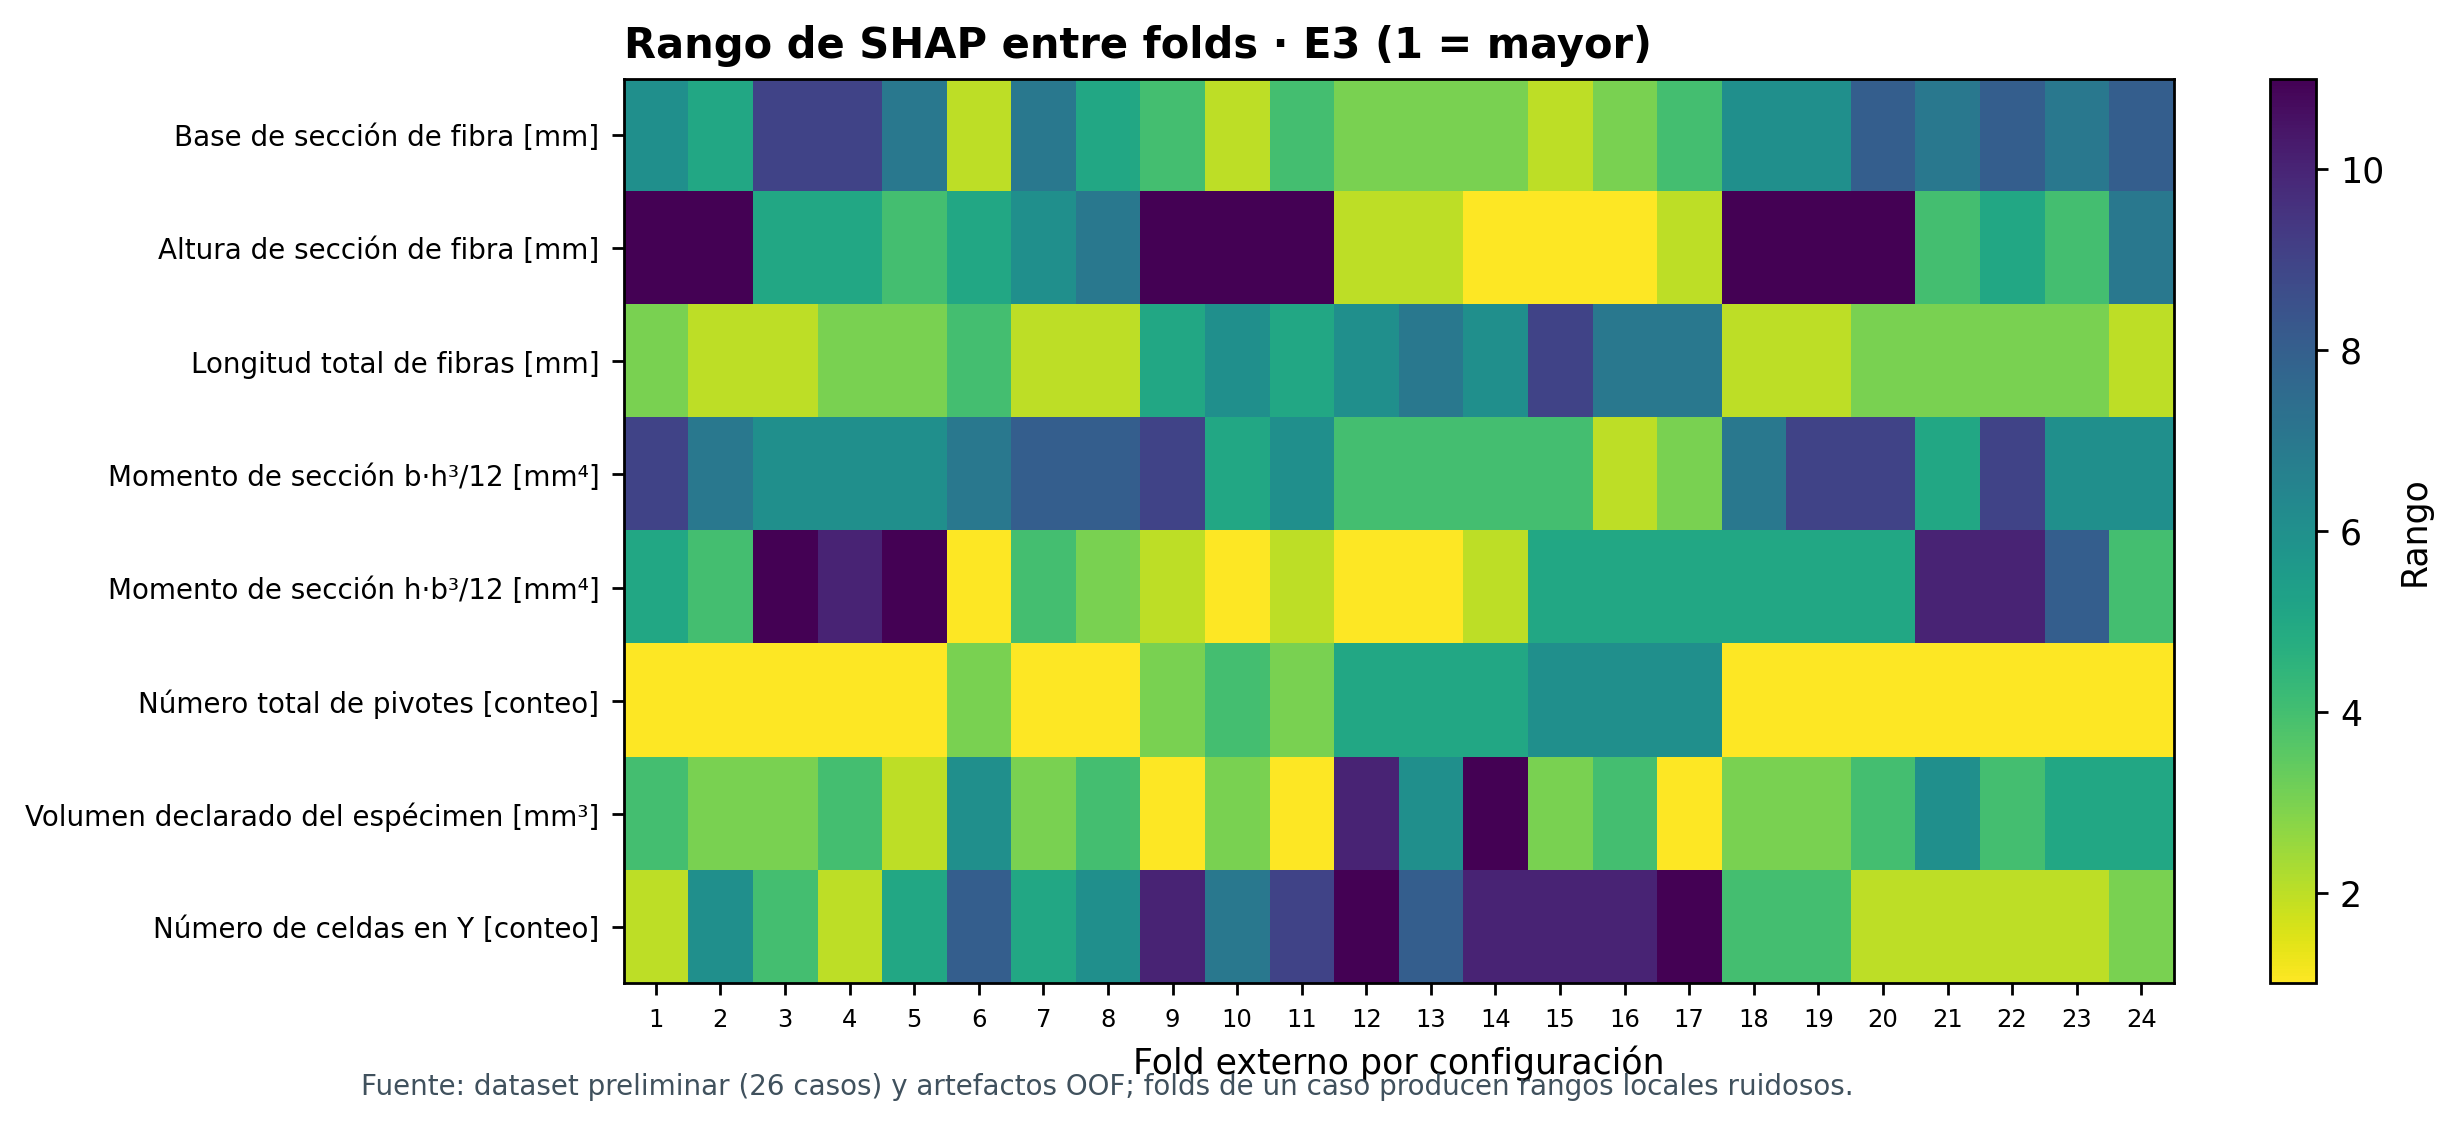

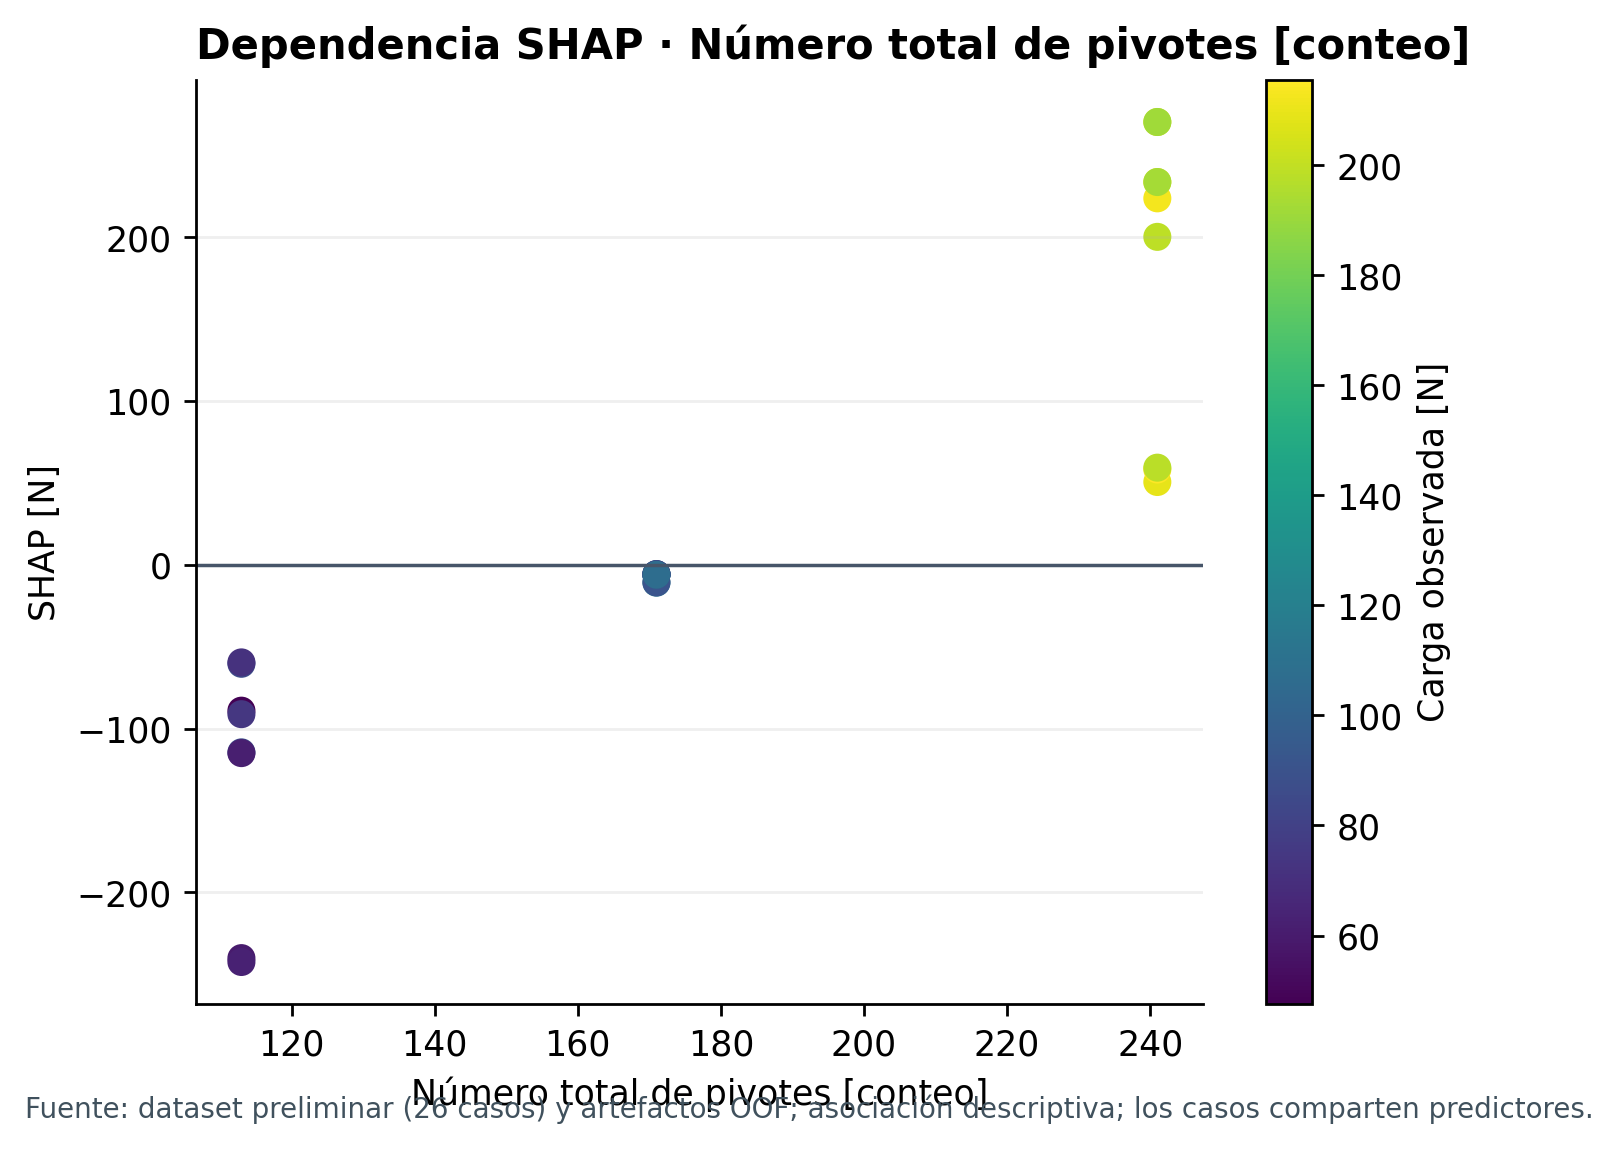

In [15]:
coef = tabla("coeficientes_folds")
signos = (coef[coef.protocolo.eq("configuracion") & coef.experimento.isin(["E3", "E4", "S3"])]
          .groupby(["experimento", "feature"])
          .coeficiente_por_z_N.agg(media="mean", sd="std",
                                   fraccion_positiva=lambda s: float((s > 0).mean()))
          .reset_index())
display(signos[signos.feature.isin(["Pivot_total_number", "n_cells_Y", "Fiber_total_length",
                                     "I_fibra_bh3_mm4", "I_fibra_hb3_mm4"])]
        .rename(columns={"experimento":"Modelo", "feature":"Variable", "media":"Coef. medio [N/z]",
                         "sd":"SD coef. [N/z]", "fraccion_positiva":"Fracción signo +"}).round(3))
estabilidad = tabla("shap_estabilidad")
top5 = (estabilidad[estabilidad.protocolo.eq("configuracion") &
                    estabilidad.experimento.isin(["E3", "E4", "S3"])]
        .groupby(["experimento", "feature"])
        .rank_fold.agg(fraccion_top5=lambda s: float((s <= 5).mean()),
                       rango_mediano="median").reset_index())
top5 = top5.merge(shap_global[["protocolo", "experimento", "feature", "rank_global"]]
                  .query("protocolo == 'configuracion'"),
                  on=["experimento", "feature"], validate="one_to_one")
display(top5.sort_values(["experimento", "rank_global"]).groupby("experimento").head(5)
        [["experimento", "feature", "fraccion_top5", "rango_mediano"]]
        .rename(columns={"experimento":"Modelo", "feature":"Variable",
                         "fraccion_top5":"Fracción top 5", "rango_mediano":"Rango mediano"}).round(3))
figura(11)
figura(9)

### Explicaciones locales: incluir un error grave

Se fijan **cuatro casos reales de Ridge E3**, todos OOF: 11 (carga observada más próxima a la mediana), 1 (mayor error absoluto), 22 (carga alta) y 5 (carga baja distinta de 1). Elegir el caso 11 favorece un buen acierto; incluir el caso 1 corrige ese sesgo de presentación. Valor base y aportes son específicos del modelo/background de cada fold.

,Caso,Motivo,Observado [N],Predicho [N],Error pred−obs [N],Base SHAP [N],Aumentan,Reducen
0,11,cerca de mediana,100.77,101.49,0.72,127.13,Base de sección de fibra +3.85 N; Volumen decl...,Volumen declarado del espécimen -17.33 N; Mome...
1,1,error máximo,47.55,89.85,42.30,129.26,Momento de sección h·b³/12 +123.28 N; Altura d...,Base de sección de fibra -103.81 N; Número tot...
2,22,carga alta,215.52,204.36,-11.16,122.54,Número total de pivotes +58.25 N; Longitud tot...,Momento de sección h·b³/12 -23.18 N; Volumen d...
3,5,carga baja,59.68,70.50,10.82,128.78,Número de celdas en Y +186.53 N; Volumen decla...,Número total de pivotes -240.11 N; Longitud to...


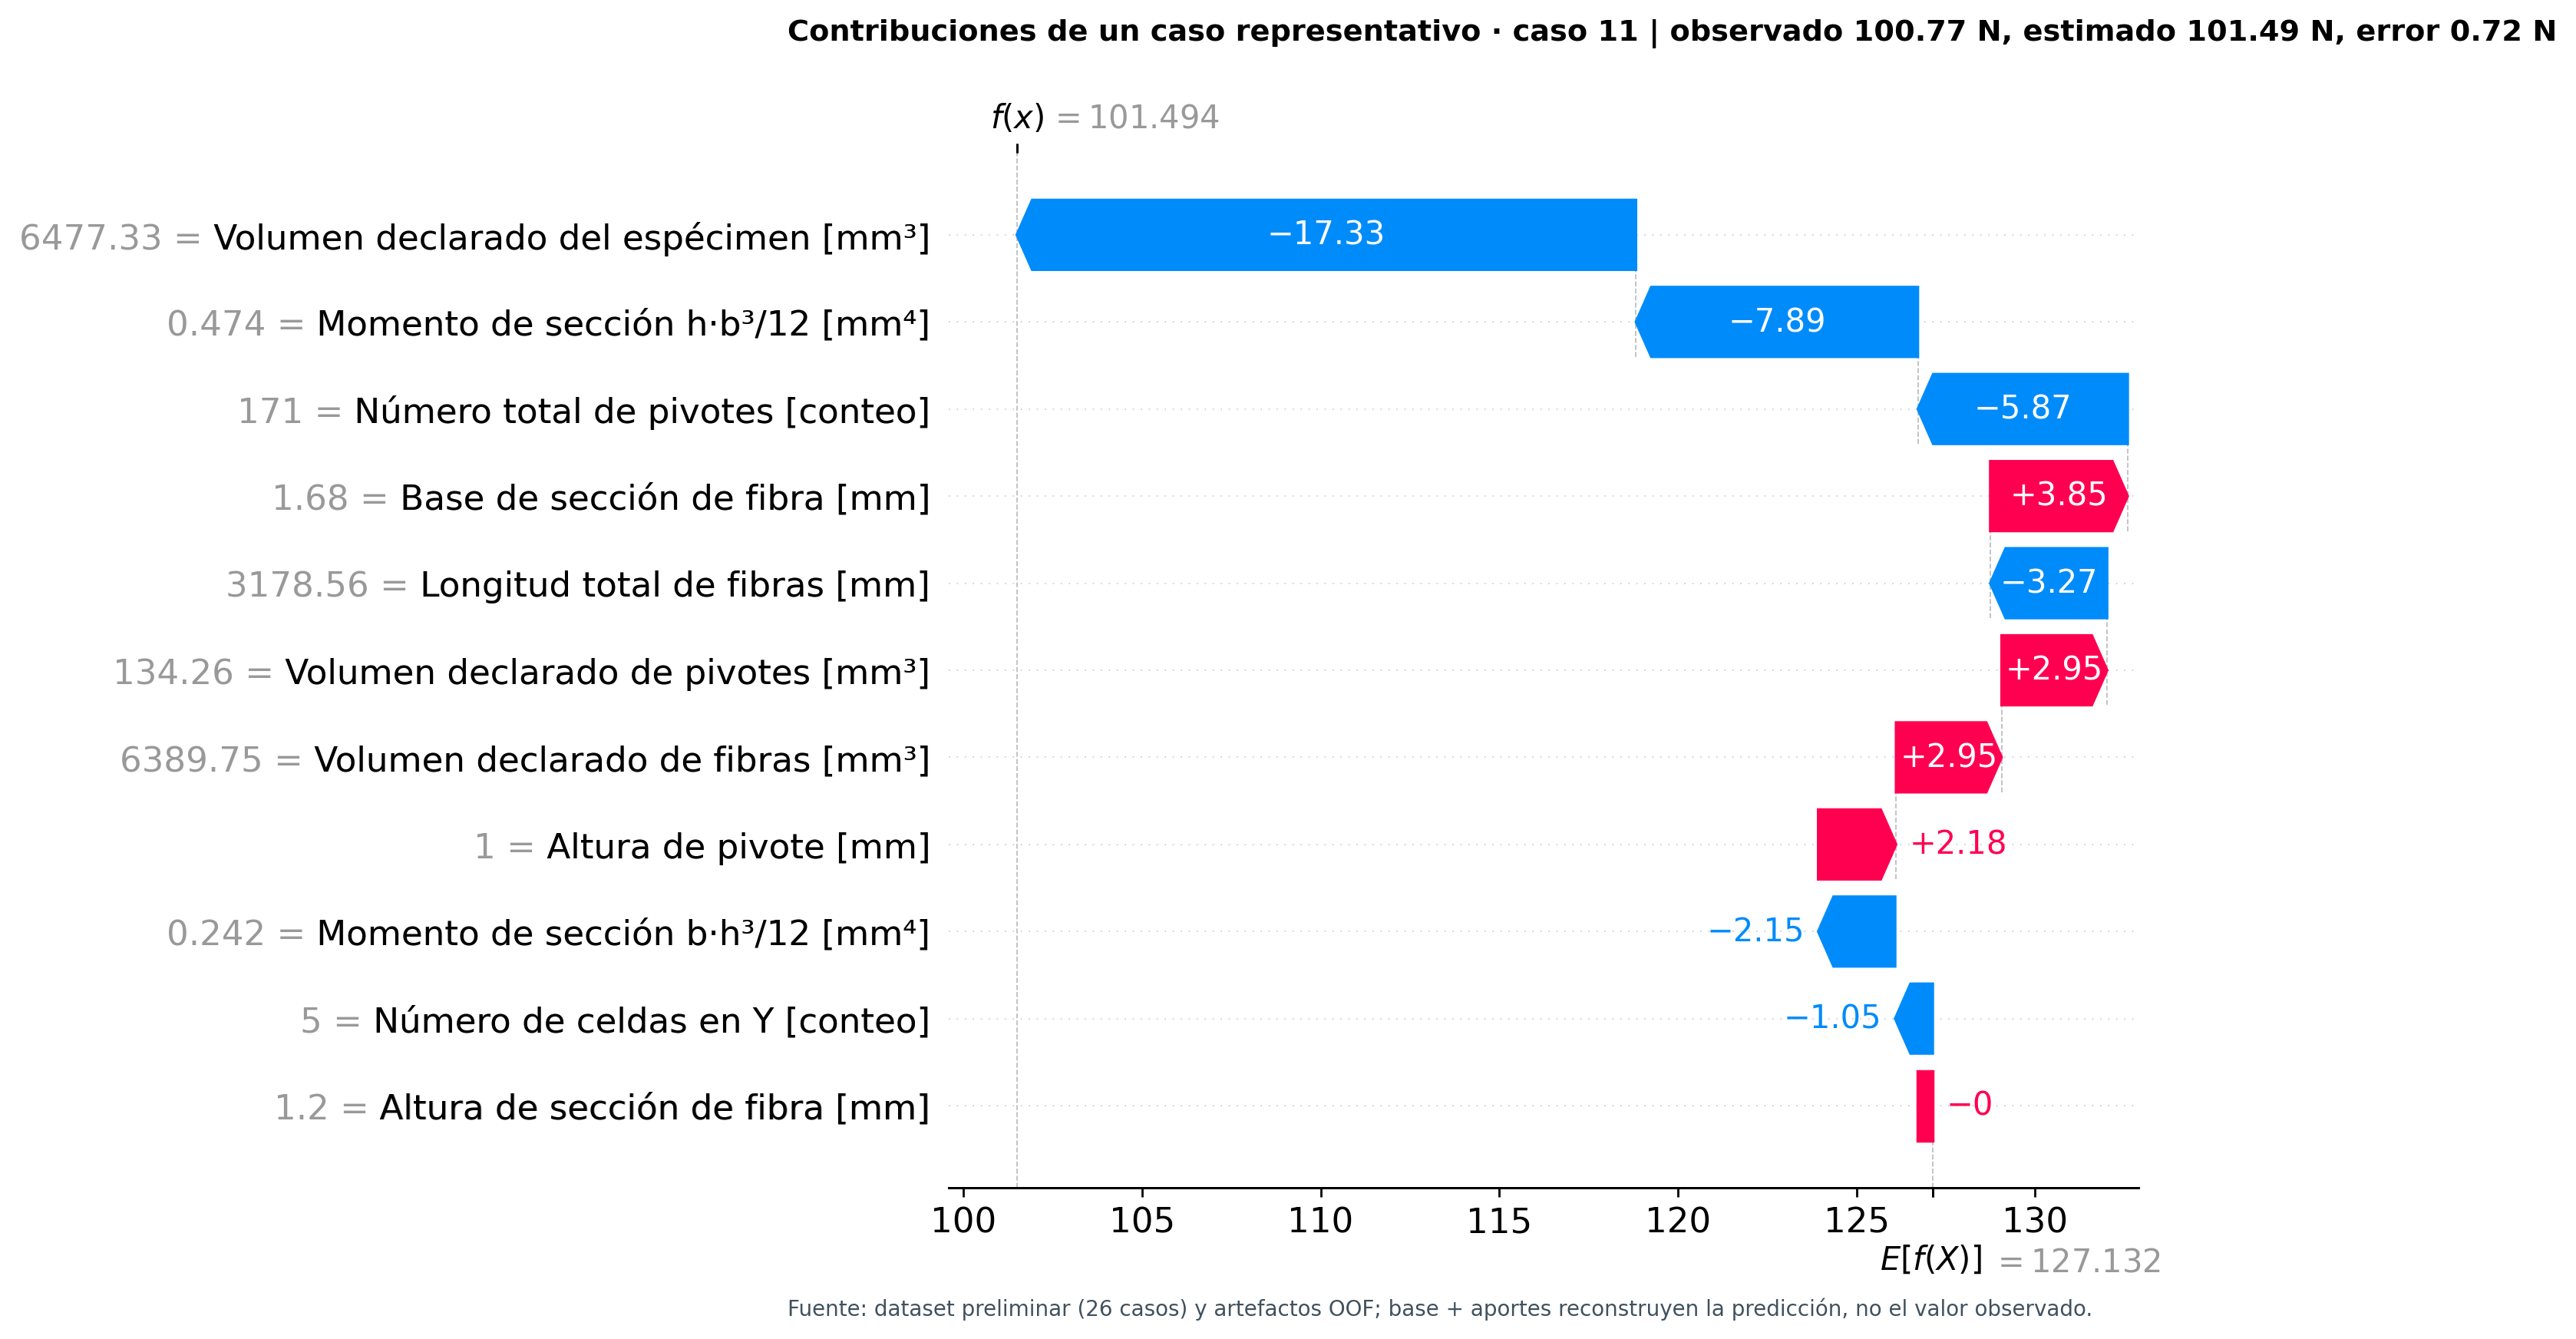

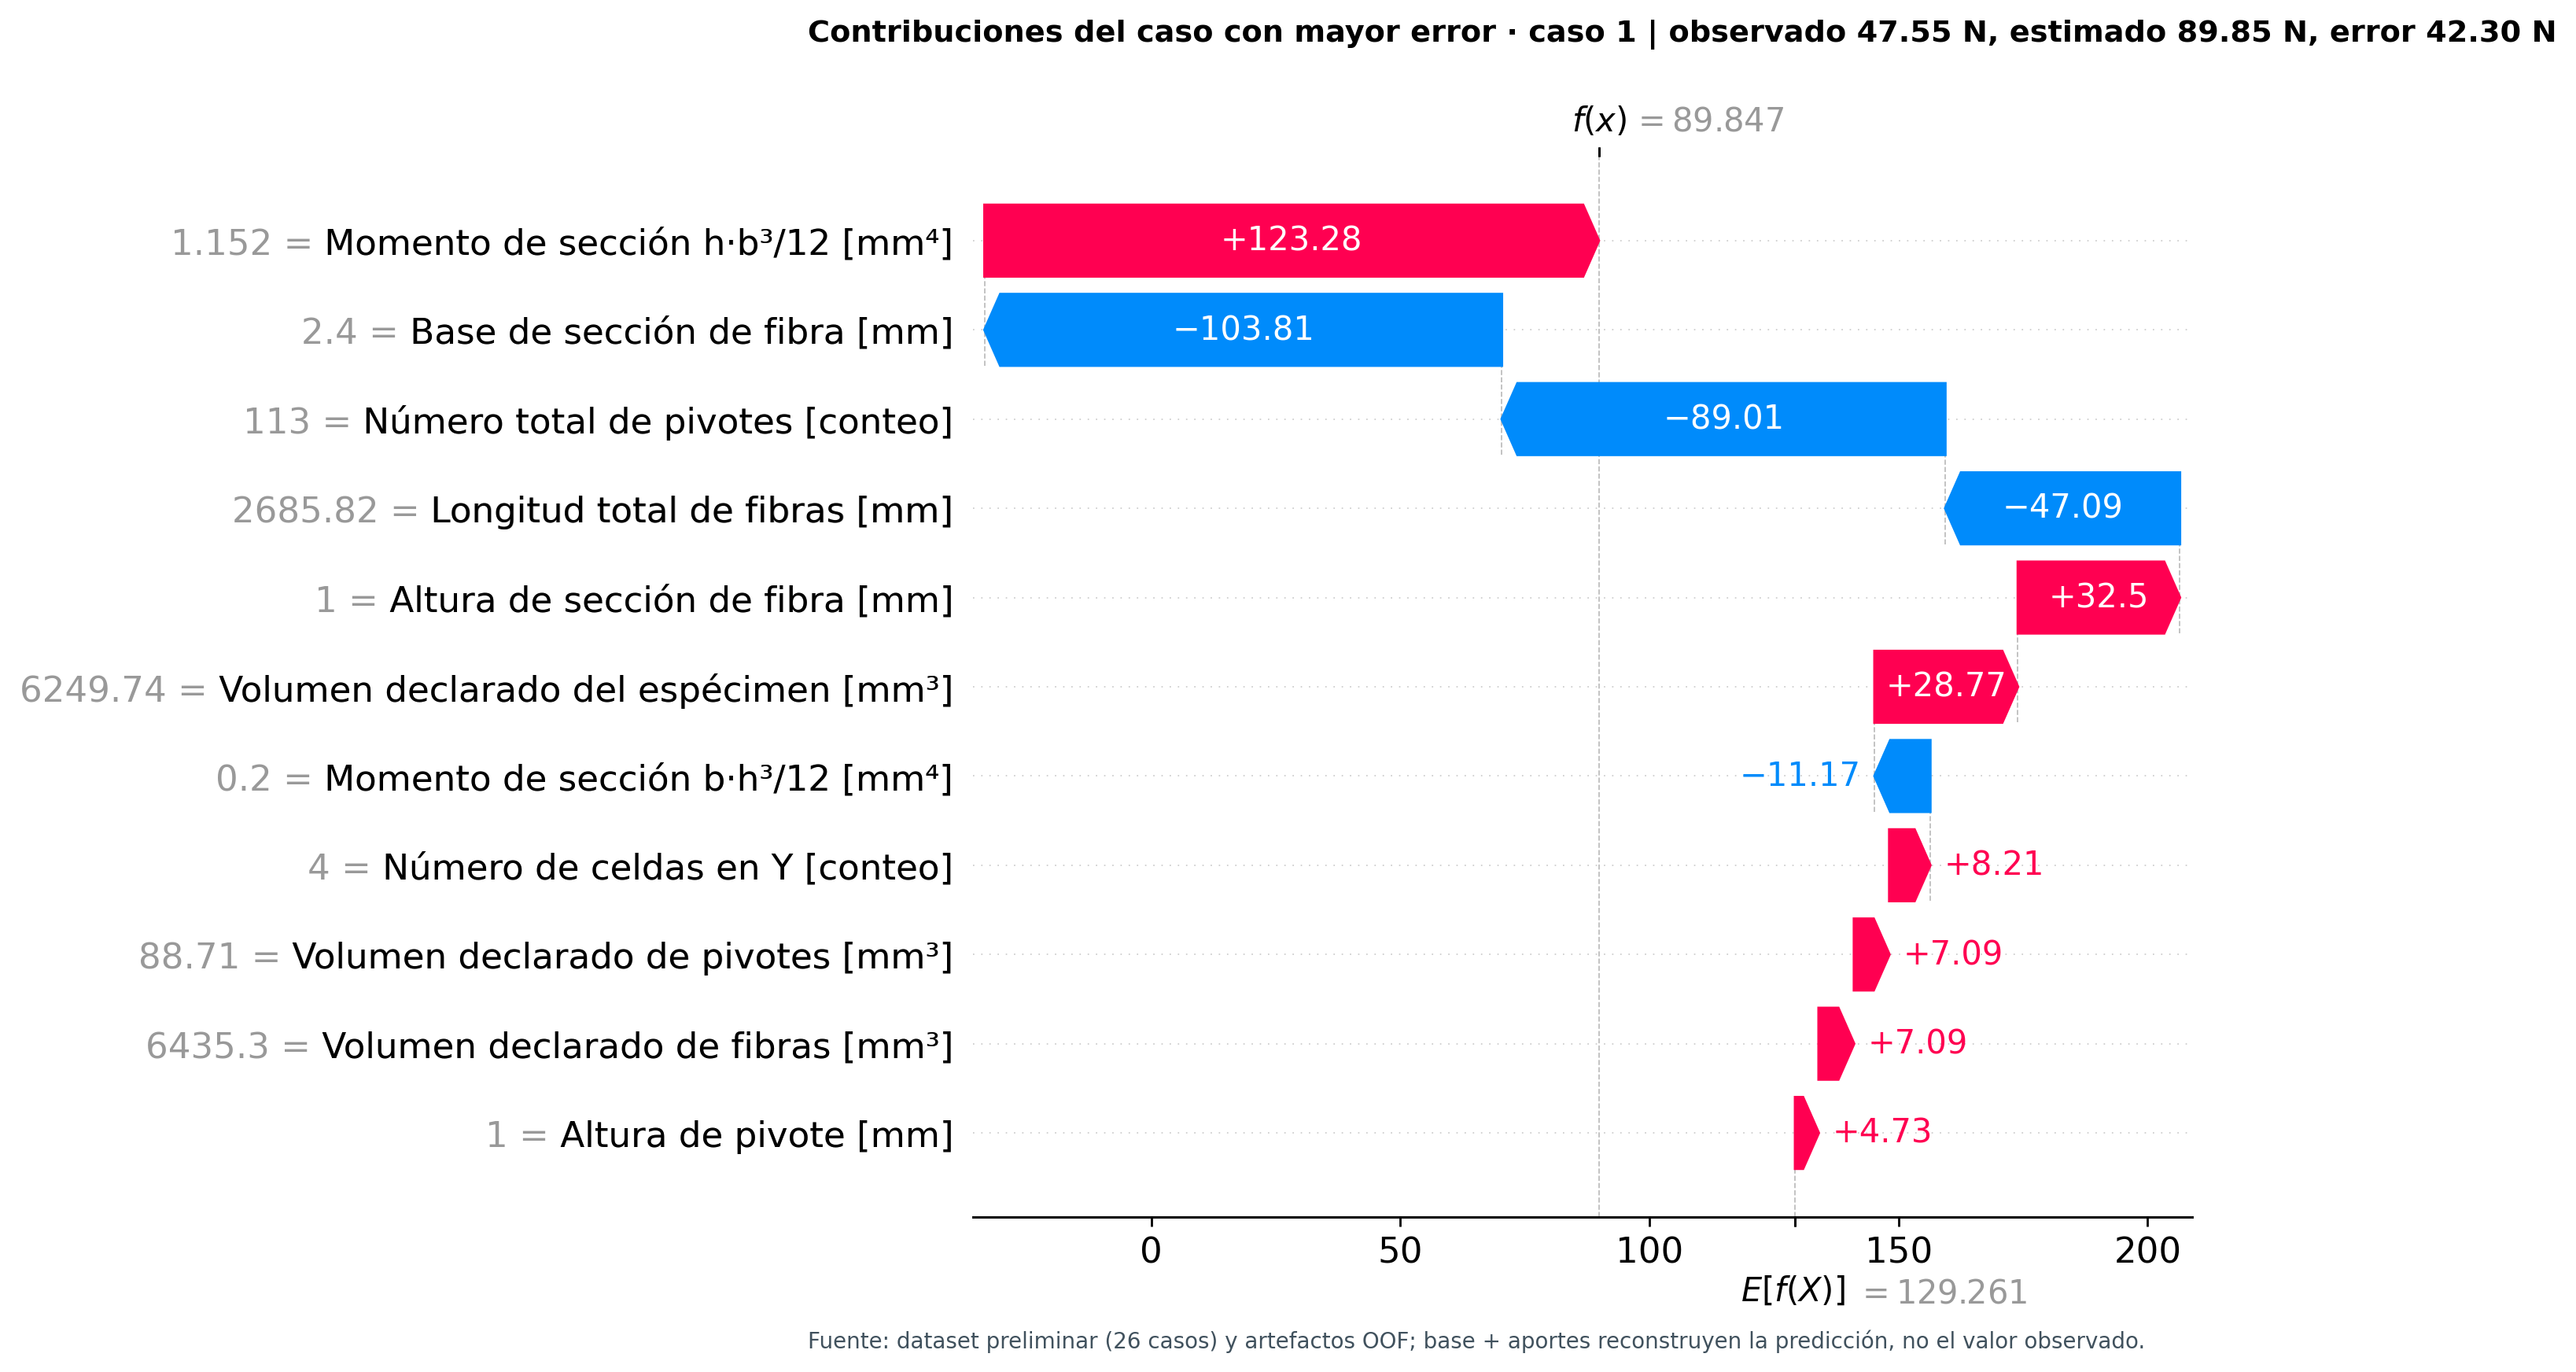

In [16]:
local = pred[pred.protocolo.eq("configuracion") & pred.experimento.eq("E3")].set_index("Case_n")
med_case = int((local.observado_N - local.observado_N.median()).abs().idxmin())
worst_case = int(local.error_absoluto_N.idxmax())
high_case = int(local.observado_N.idxmax())
low_case = int(local.observado_N.nsmallest(2).index[-1])
assert [med_case, worst_case, high_case, low_case] == [11, 1, 22, 5]
motivos = {11:"cerca de mediana", 1:"error máximo", 22:"carga alta", 5:"carga baja"}
rows = []
for case in [11, 1, 22, 5]:
    p = local.loc[case]
    v = shap_oof[shap_oof.protocolo.eq("configuracion") & shap_oof.experimento.eq("E3") &
                 shap_oof.Case_n.eq(case)].copy()
    pos = v.nlargest(3, "shap_N")
    neg = v.nsmallest(3, "shap_N")
    fmt = lambda t: "; ".join(f"{LABELS.get(r.feature,r.feature).split(' [')[0]} {r.shap_N:+.2f} N" for r in t.itertuples())
    assert np.isclose(v.base_N.iloc[0] + v.shap_N.sum(), p.predicho_N, atol=1e-6)
    rows.append({"Caso":case, "Motivo":motivos[case], "Observado [N]":p.observado_N,
                 "Predicho [N]":p.predicho_N, "Error pred−obs [N]":p.predicho_N-p.observado_N,
                 "Base SHAP [N]":v.base_N.iloc[0], "Aumentan":fmt(pos), "Reducen":fmt(neg)})
display(pd.DataFrame(rows).round(2))
figura(7)
figura(8)

**Lectura local.** Caso 11: **100,77 N** observados, **101,49 N** estimados, error **+0,72 N**; volumen CAD y momento h·b³/12 reducen la base de **127,13 N**. Caso 1: **47,55 N** observados frente a **89,85 N** estimados (error **+42,30 N**); aportes de hasta centenares de N se cancelan, pero el modelo sobreestima el inicio de falla. Caso 22 (215,52 N observados) presenta aportes positivos de arquitectura; caso 5 muestra cancelación entre celdas y pivotes. Estas son descripciones del predictor y motivan hipótesis mecánicas, no reglas de fractura.

## 7 · Importancia por permutación, correlación y ablación

La permutación usa `MAE_permutado − MAE_original` con 12 repeticiones. Muchos folds por configuración tienen un solo caso; por eso el runner permuta fuentes entre los 26 casos OOF y predice cada caso con **su modelo del fold externo**. Esta perturbación puede crear geometrías fuera del soporte y romper dependencias. Las variables derivadas se recalculan desde sus fuentes: una permutación de altura/base afecta ambos momentos. Se muestra también un grupo de fuentes de sección y otro de volúmenes.

,Fuente o grupo,ΔMAE medio [N],SD [N],Repeticiones
6,Pivot_total_number,100.737,20.799,12
9,n_cells_Y,60.512,13.388,12
2,Fiber_total_length,34.111,7.117,12
8,Sample_total_volume,20.039,3.387,12
0,Fiber_base,7.093,2.251,12
11,volumenes_componentes,7.066,1.731,12
10,seccion_fibra_fuentes,3.395,1.753,12
1,Fiber_height,3.221,1.971,12
7,Pivot_total_volume,2.466,1.153,12
3,Fiber_total_volume,2.348,1.084,12


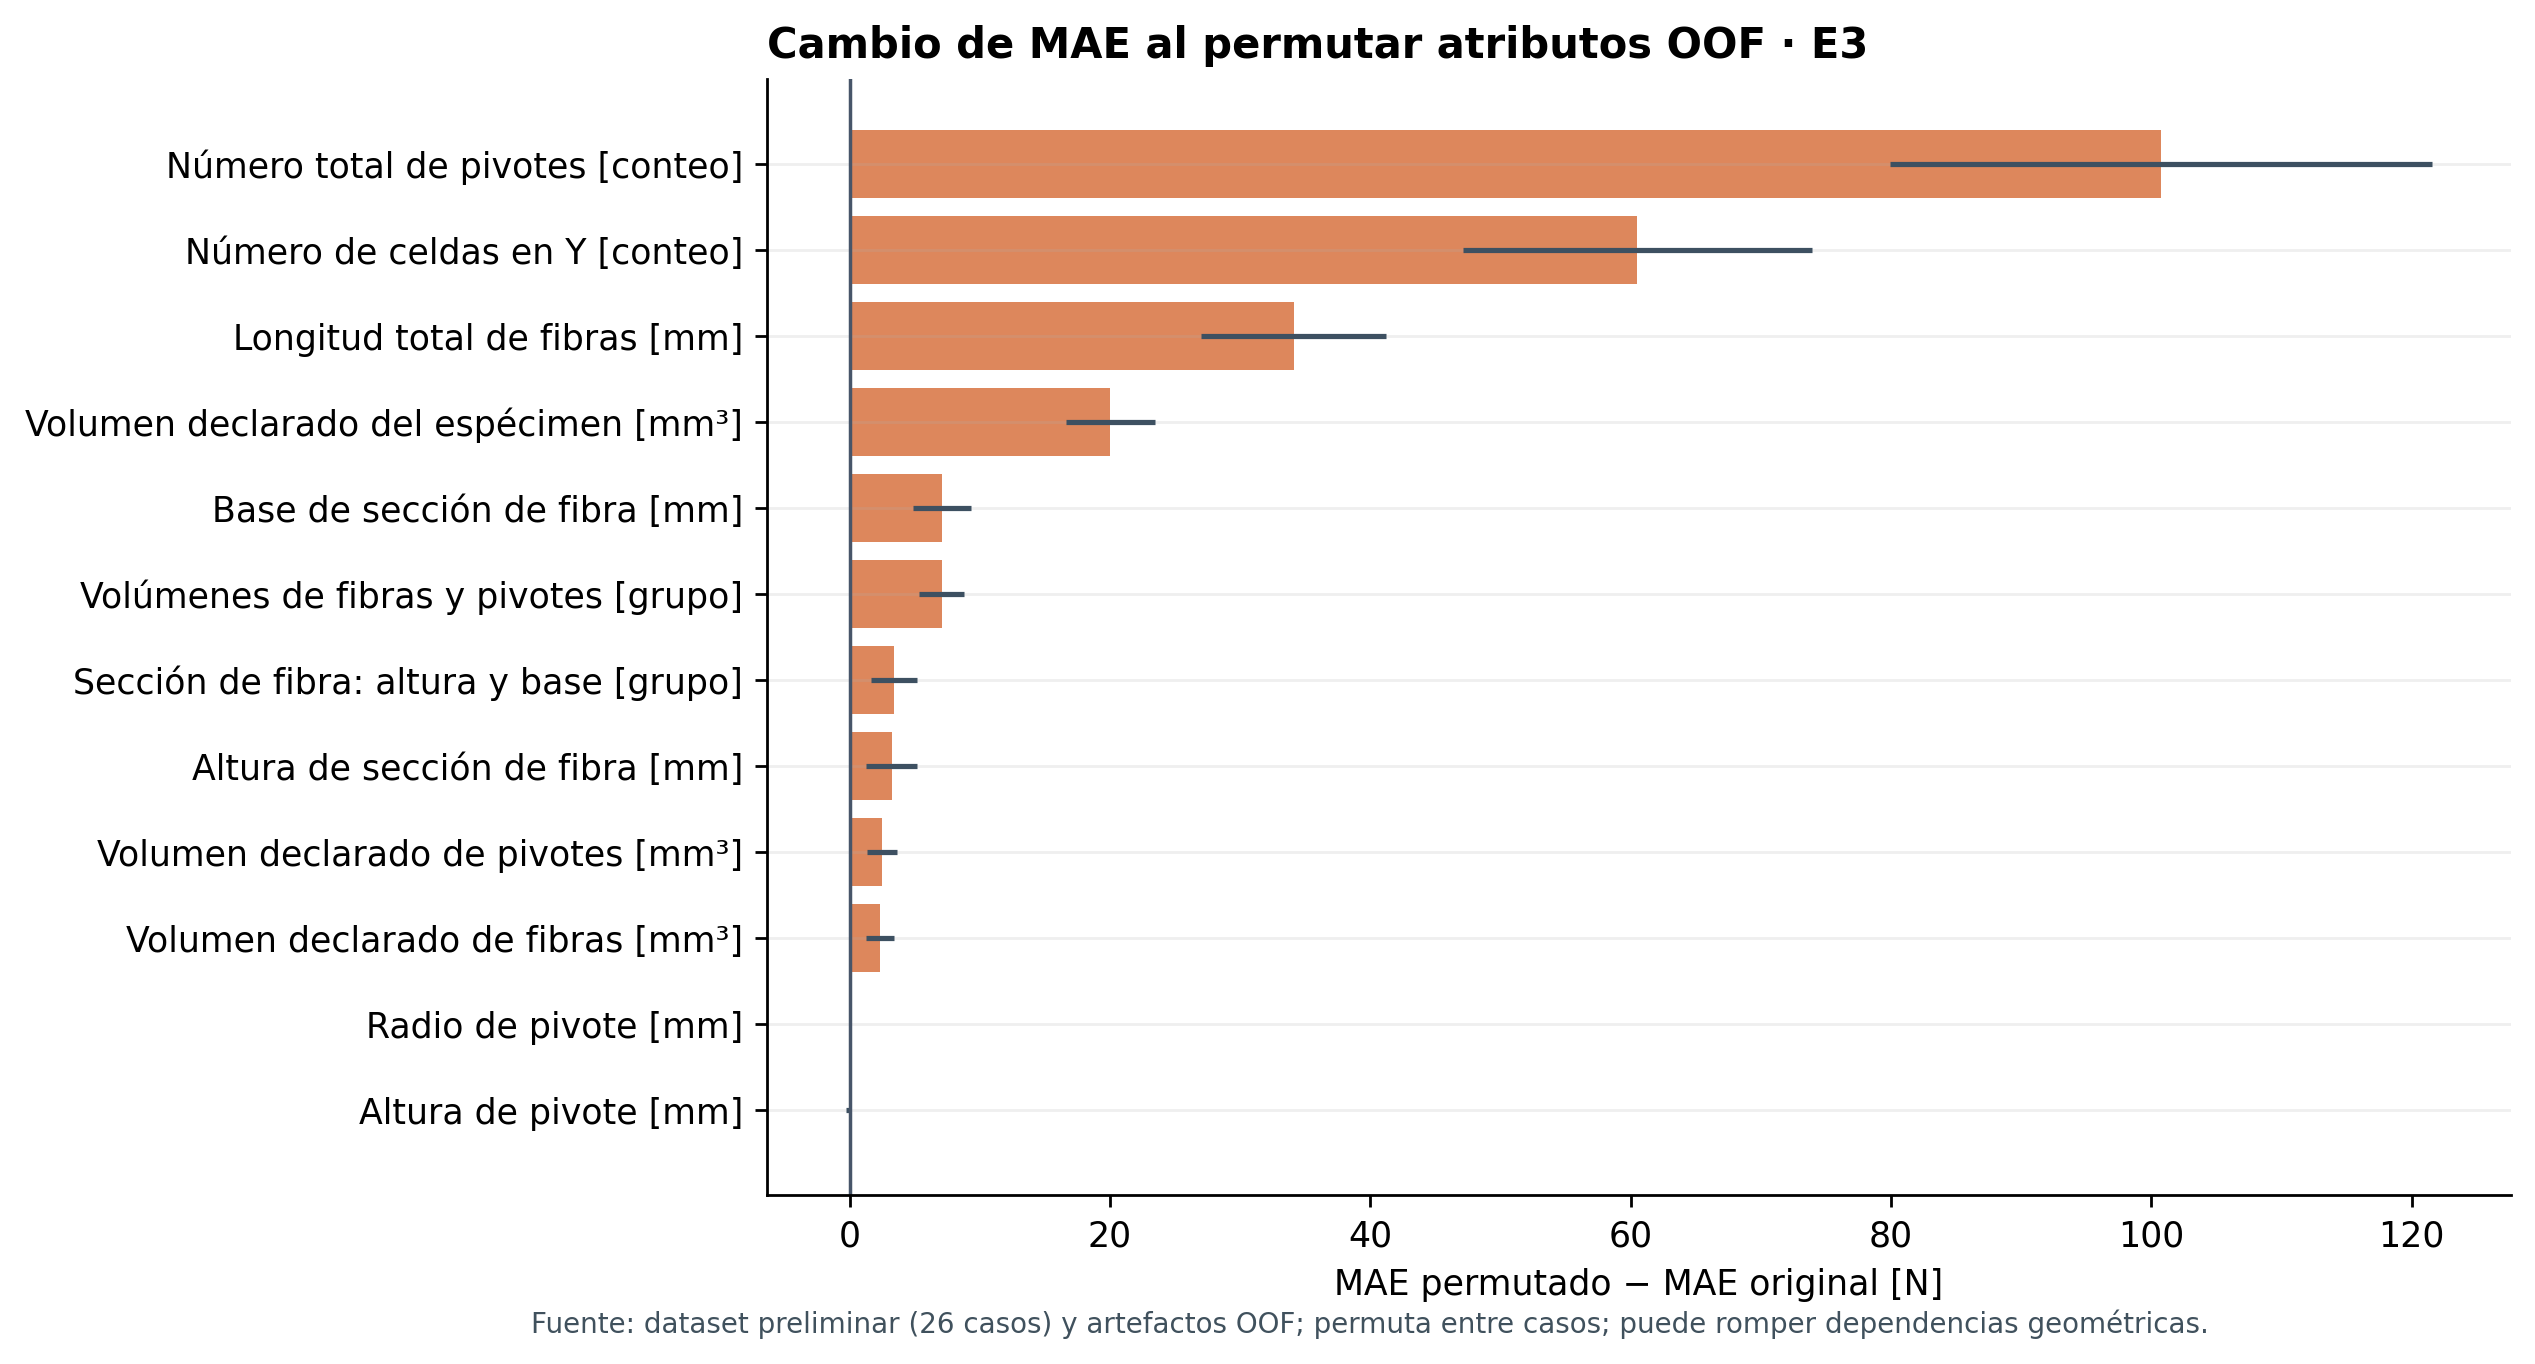

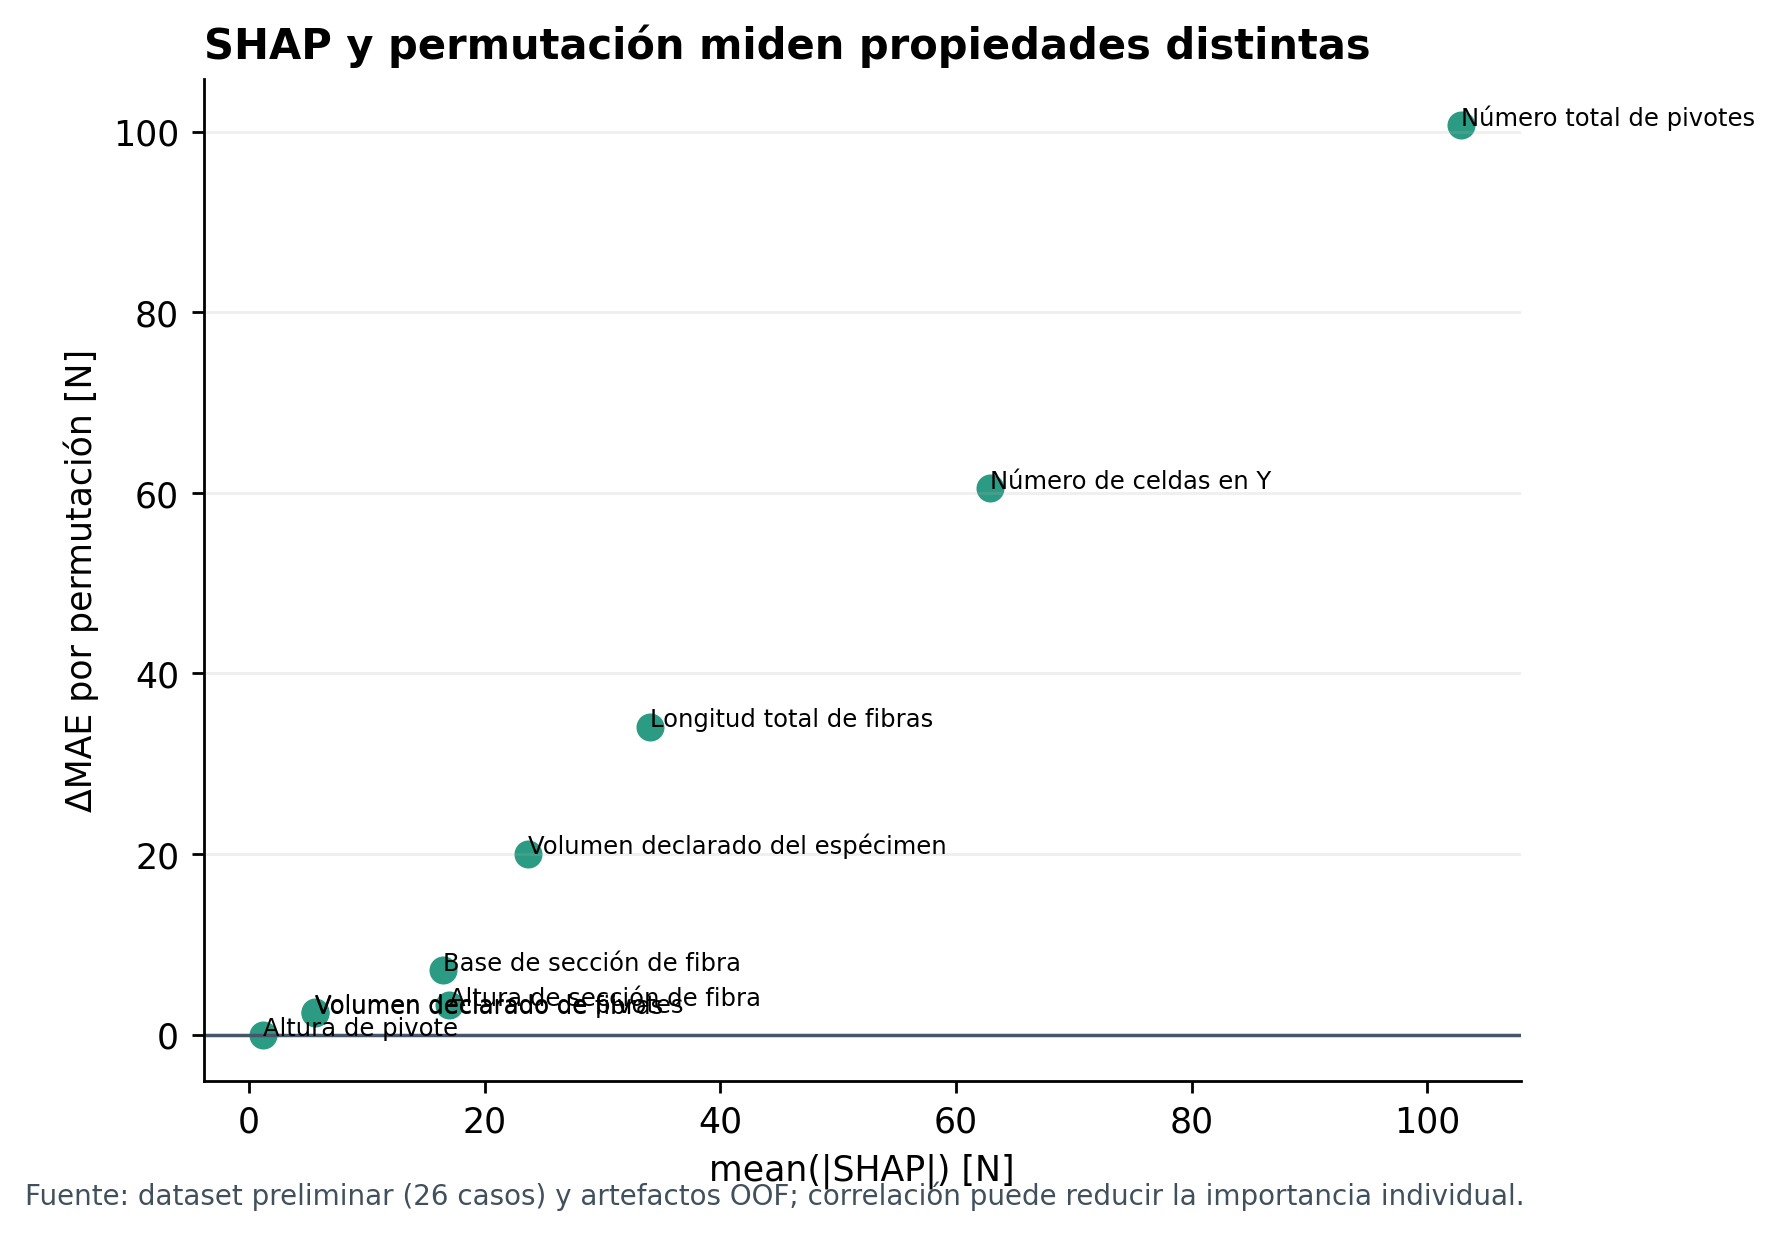

In [17]:
perm = tabla("permutacion")
p = perm[perm.protocolo.eq("configuracion") & perm.experimento.eq("E3")]
display(p.sort_values("importancia_media_N", ascending=False)
        [["feature_or_group", "importancia_media_N", "importancia_sd_N", "n_repeticiones"]]
        .rename(columns={"feature_or_group":"Fuente o grupo", "importancia_media_N":"ΔMAE medio [N]",
                         "importancia_sd_N":"SD [N]", "n_repeticiones":"Repeticiones"}).round(3))
figura(12)
figura(13)

**Concordancia y discrepancia.** Permutar número de pivotes aumenta el MAE de E3 **100,74 ± 20,80 N** y permutar celdas Y **60,51 ± 13,39 N**; coinciden con el orden superior de SHAP individual. Esa concordancia indica dependencia predictiva del modelo bajo la perturbación aplicada, no impacto físico independiente. Altura de pivote muestra importancia media próxima a cero; no prueba irrelevancia para radios o arquitecturas no observadas.

,Variable 1,Variable 2,Pearson r,Spearman ρ
36,Fiber_total_volume,Pivot_total_volume,-1.0000,-1.0000
29,Fiber_total_length,Pivot_total_number,0.9997,1.0000
2,n_cells_Y,Fiber_total_length,0.9995,1.0000
5,n_cells_Y,Pivot_total_number,0.9985,1.0000
26,Fiber_base,I_fibra_hb3_mm4,0.9735,0.9818
17,Fiber_height,I_fibra_bh3_mm4,0.9317,0.9440
7,n_cells_Y,Sample_total_volume,0.9195,0.9043
45,Pivot_total_number,Pivot_total_volume,0.9122,0.9488


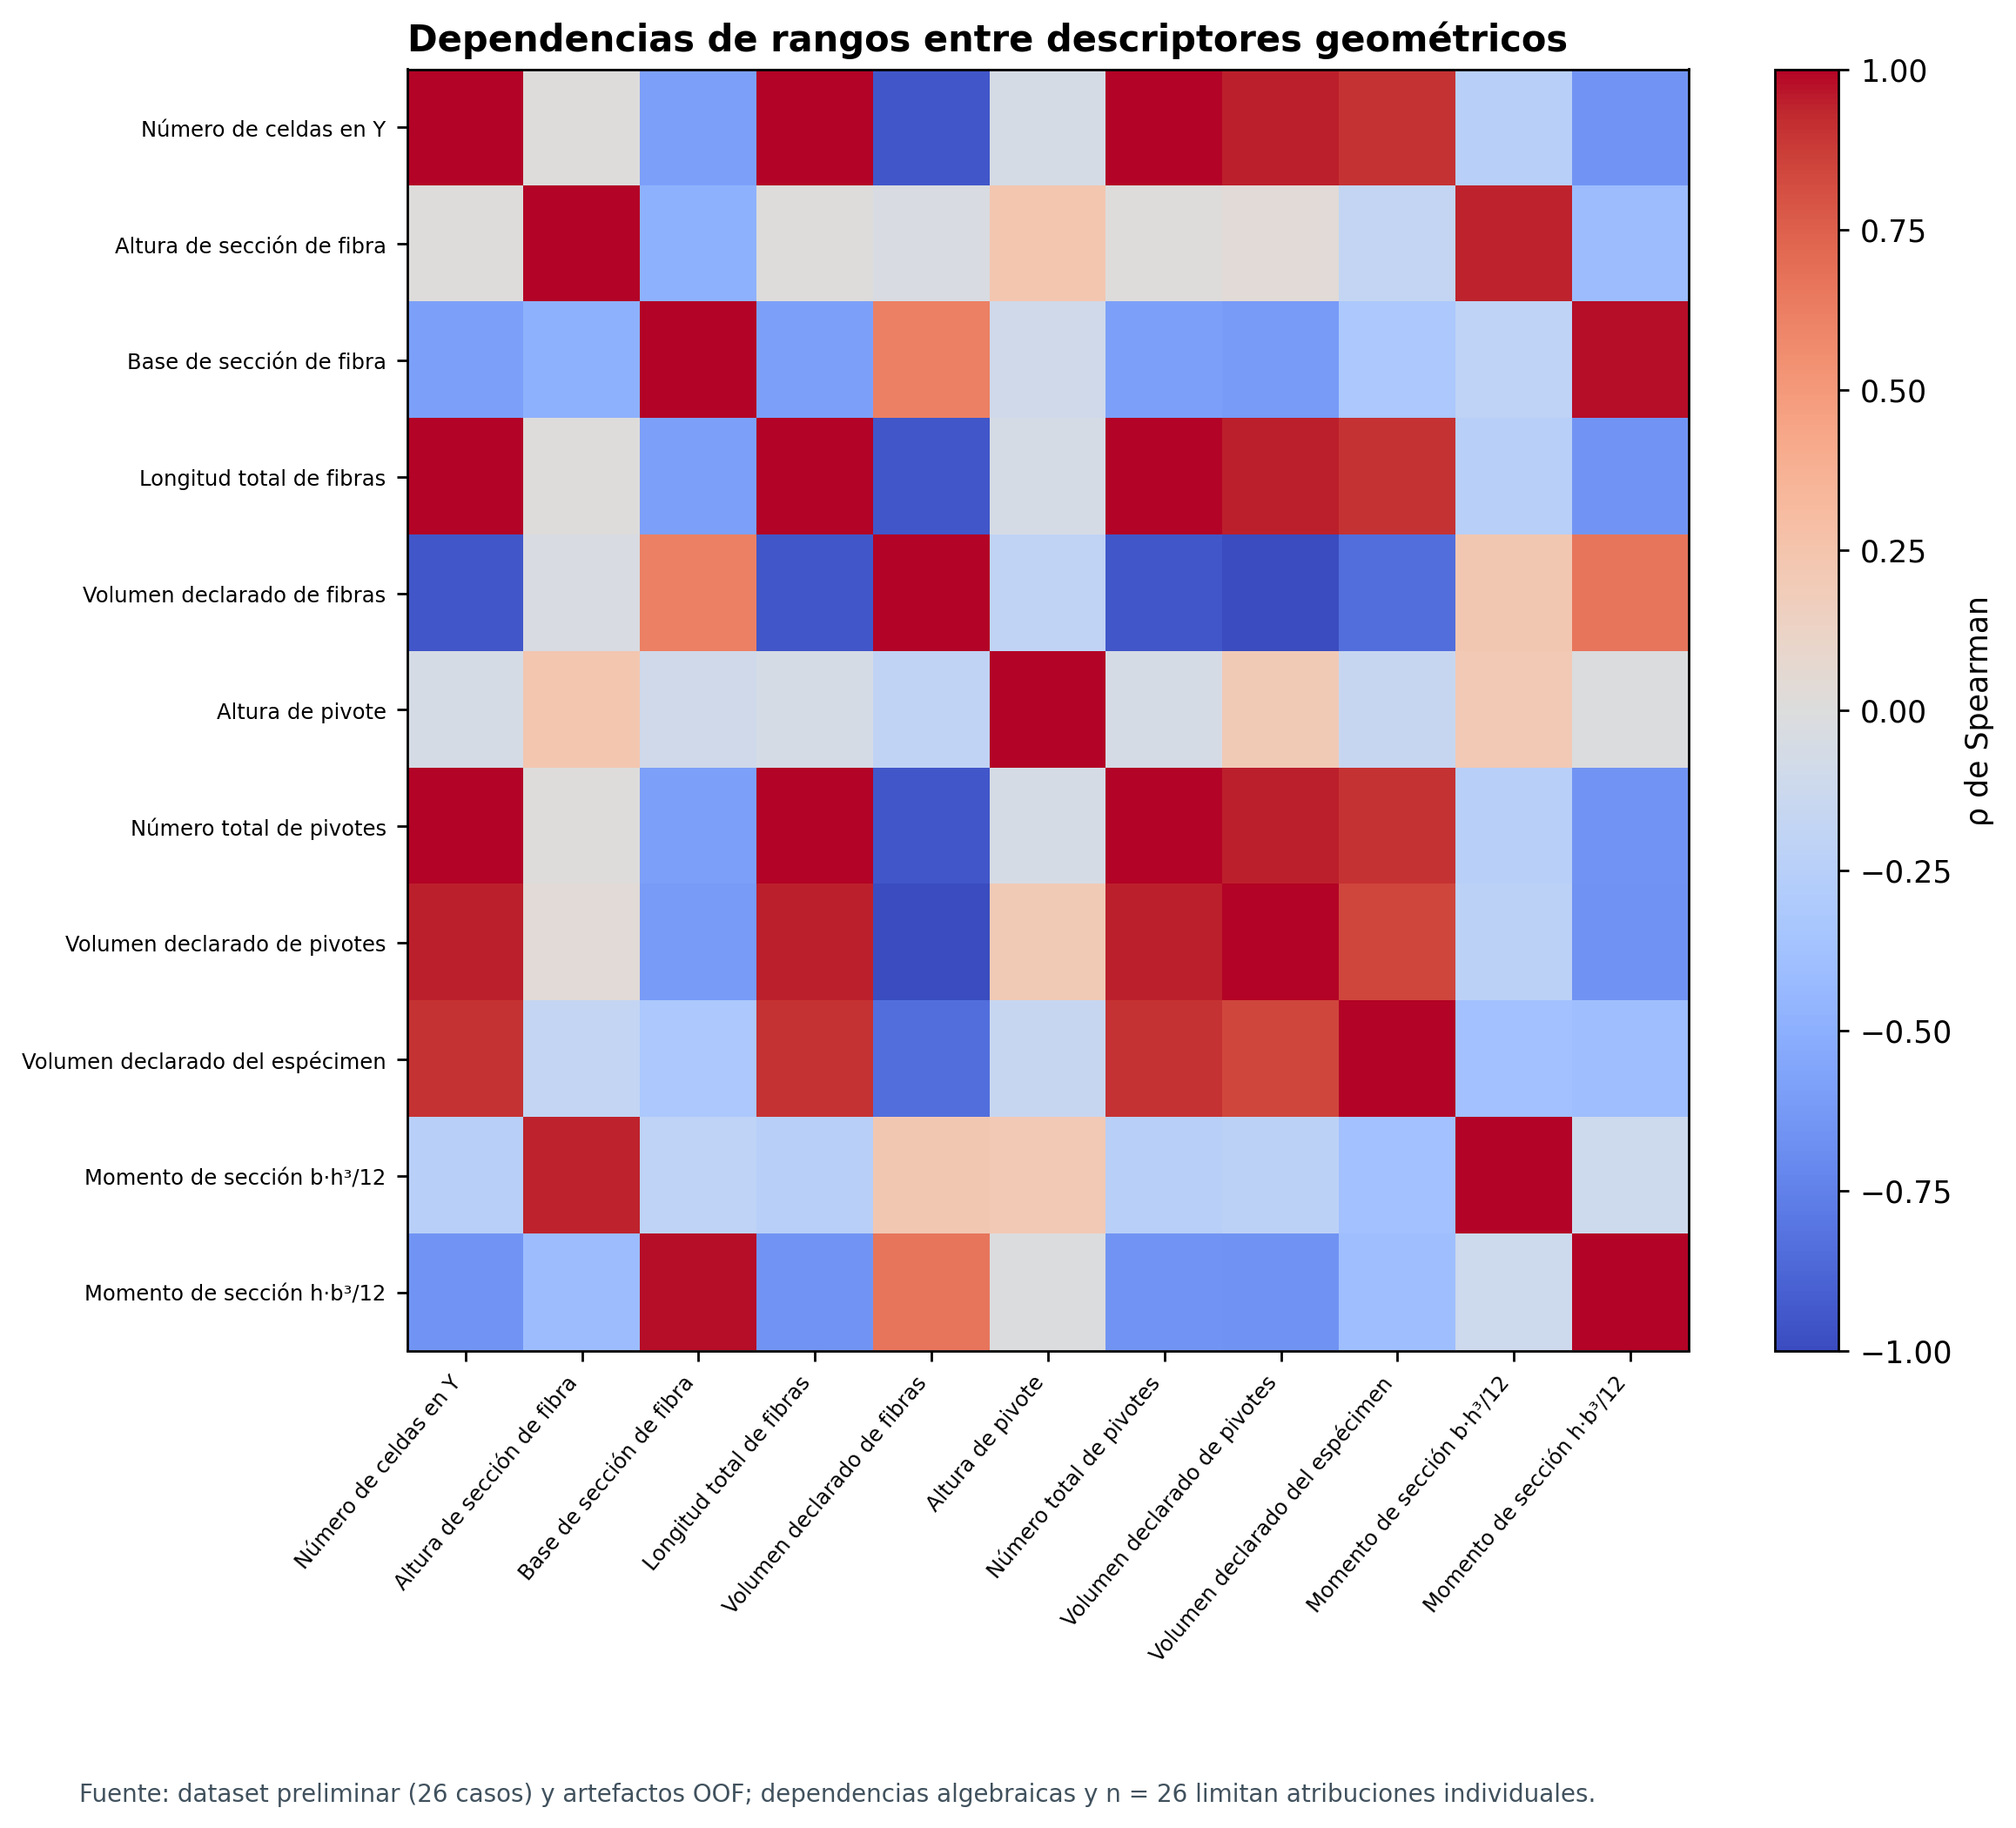

In [18]:
correlaciones = tabla("correlaciones")
top_corr = correlaciones.assign(abs_r=correlaciones.pearson_r.abs()).nlargest(8, "abs_r")
display(top_corr[["feature_1", "feature_2", "pearson_r", "spearman_rho"]]
        .rename(columns={"feature_1":"Variable 1", "feature_2":"Variable 2",
                         "pearson_r":"Pearson r", "spearman_rho":"Spearman ρ"}).round(4))
figura(14)

**Redundancia medida.** Volumen de fibras y de pivotes tienen correlación de Pearson **−1,0000** en esta tabla; longitud de fibras y número de pivotes **0,9997**; celdas Y y longitud de fibras **0,9995**. Los momentos comparten sus fuentes: `Fiber_base` con h·b³/12 tiene **0,9735**, y `Fiber_height` con b·h³/12 **0,9317**. Esto vuelve inestable repartir el crédito entre atributos individuales. El análisis de bloque ayuda a detectar información compartida.

La diapositiva 4 de IA06 propone revisar VIF. Con una dependencia lineal **exacta** entre los dos volúmenes declarados, el VIF individual no es finito o estable; se informa la correlación y la identidad algebraica en lugar de inventar un VIF numérico.

,Validación,Completo B,Sin momentos A,MAE sin − completo [N],Fracción casos mejora al retirar,SD Δerror [N]
0,configuracion,E2,E1,0.412,0.423,2.148
1,configuracion,E3,E4,-1.274,0.538,4.871
2,configuracion,S2,S1,0.538,0.423,2.189
3,configuracion,S3,S4,-0.692,0.462,4.484
4,familia,E2,E1,-0.016,0.654,2.058
5,familia,E3,E4,6.419,0.462,18.009
6,familia,S2,S1,0.017,0.615,1.488
7,familia,S3,S4,-2.592,0.962,1.466


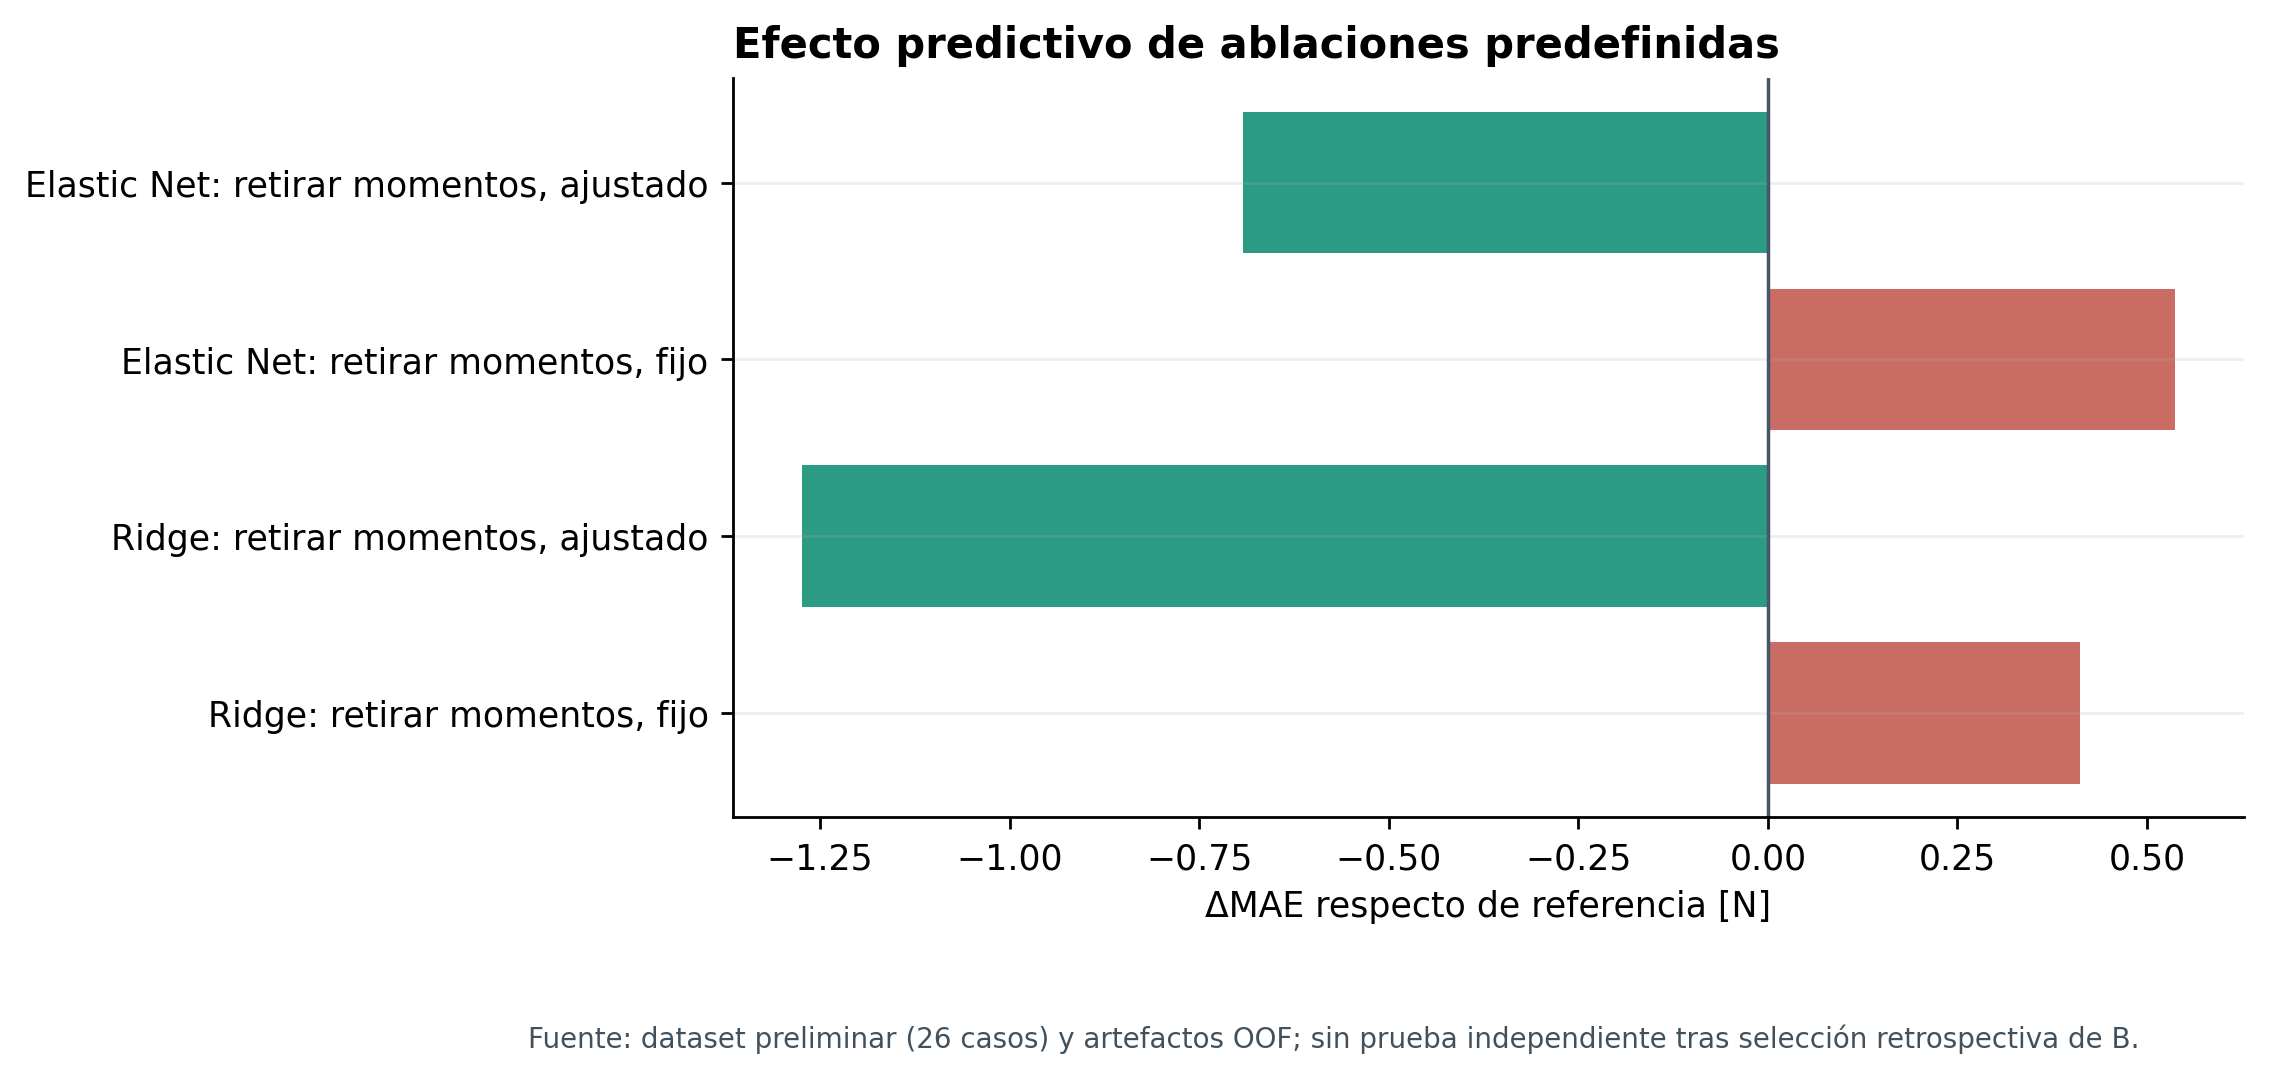

In [19]:
abl = tabla("ablaciones")
display(abl[["protocolo", "referencia", "intervencion", "delta_MAE_N",
             "fraccion_casos_mejora", "sd_delta_error_absoluto_N"]]
        .rename(columns={"protocolo":"Validación", "referencia":"Completo B",
                         "intervencion":"Sin momentos A", "delta_MAE_N":"MAE sin − completo [N]",
                         "fraccion_casos_mejora":"Fracción casos mejora al retirar",
                         "sd_delta_error_absoluto_N":"SD Δerror [N]"}).round(3))
figura(15)

**Ablación con reentrenamiento.** Retirar ambos momentos de B aumenta el MAE de Ridge fijo **0,4119 N** y Elastic Net fijo **0,5375 N** al reservar configuraciones. Tras retuning equivalente, retirarlos **reduce** el MAE **1,2744 N** en Ridge y **0,6920 N** en Elastic Net. SHAP puede atribuir magnitud local a los momentos aun cuando su bloque no mejore el rendimiento del modelo ajustado. Los métodos miden propiedades distintas; no se vota por rankings.

experimento,E3,E4,S3
familia_geometrica,,,
arquitectura,85.25,82.10,88.13
pivotes,5.89,6.16,4.90
seccion_fibra,9.38,3.49,9.62
volumen_global_y_fibras,28.58,21.81,31.75


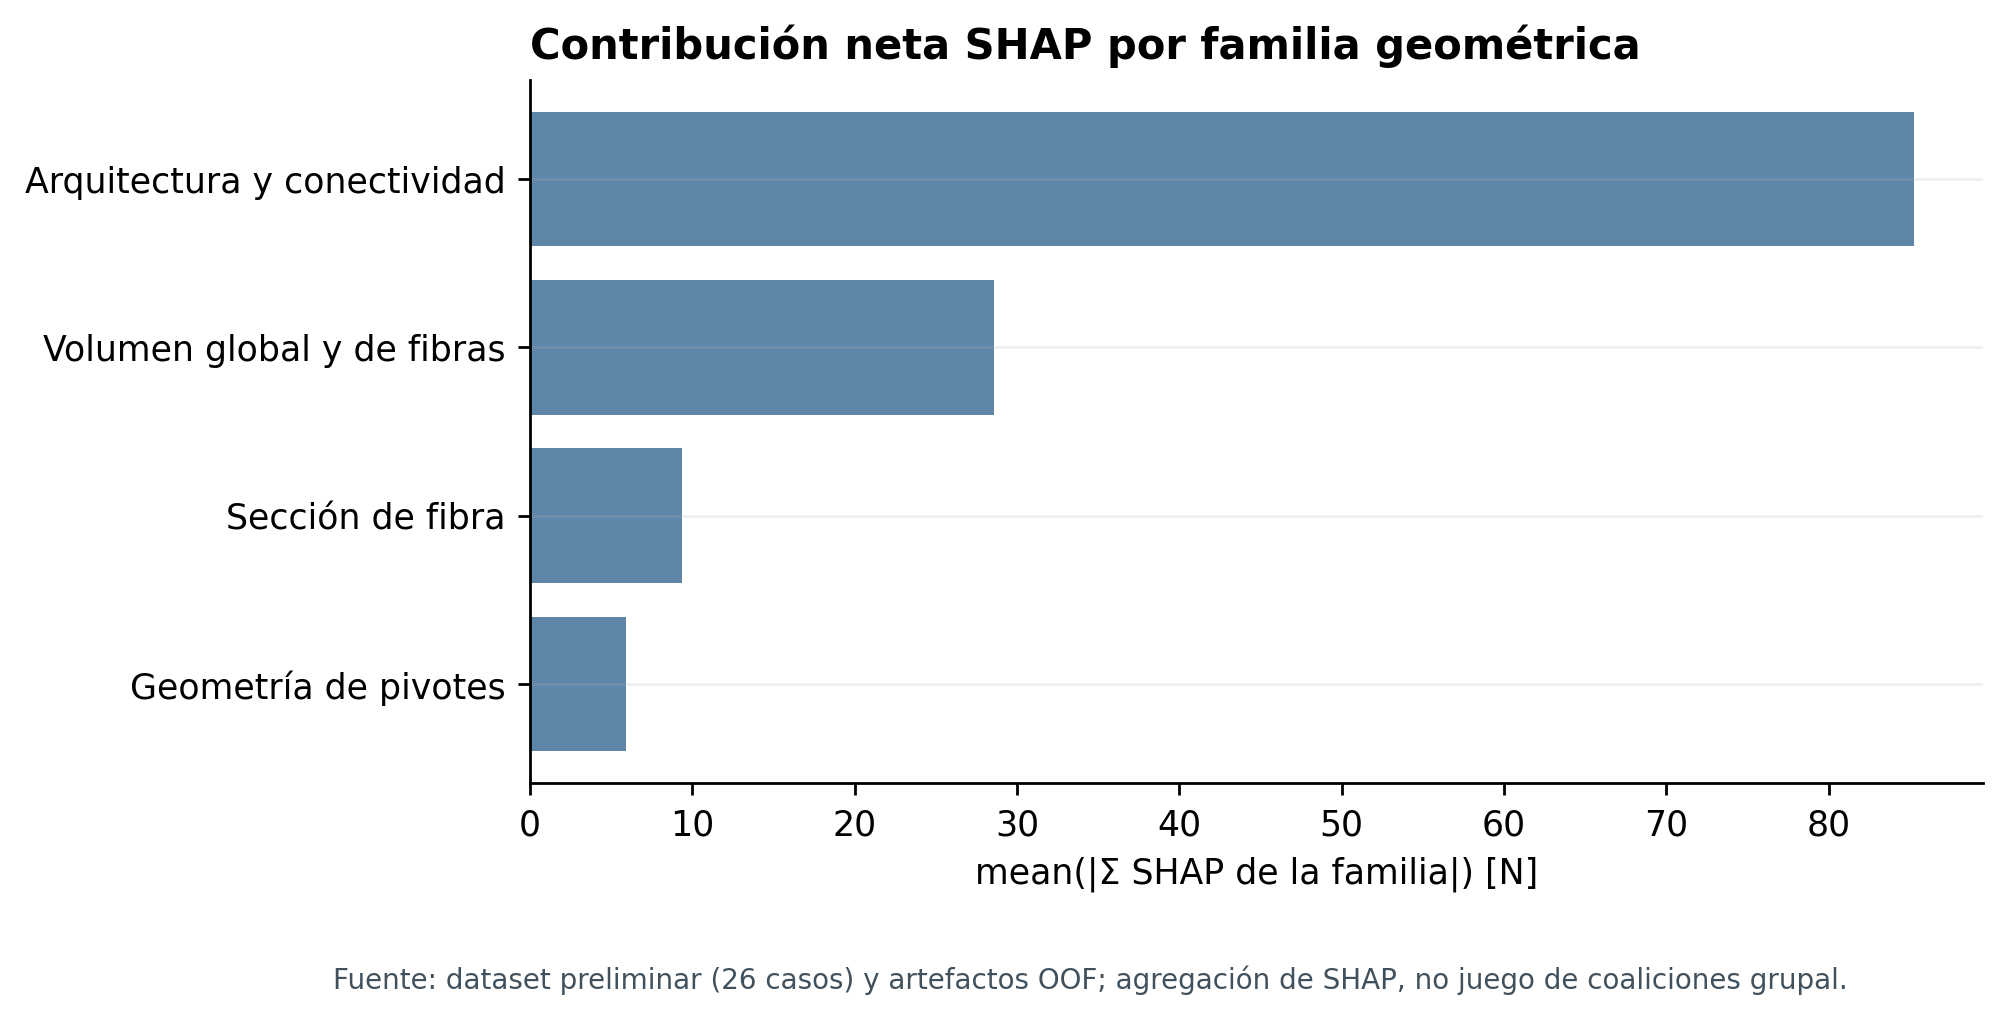

In [20]:
familias_shap = tabla("shap_familias")
familias_resumen = (familias_shap[familias_shap.protocolo.eq("configuracion") &
                                familias_shap.experimento.isin(["E3", "S3", "E4"])]
                    .groupby(["experimento", "familia_geometrica"], as_index=False)
                    .mean_abs_sum_shap_N.first())
display(familias_resumen.pivot(index="familia_geometrica", columns="experimento",
                               values="mean_abs_sum_shap_N").round(2))
figura(16)

Esta familia suma primero los SHAP **con signo en cada caso** y luego calcula `mean(|suma|)`: en E3, arquitectura **85,25 N** y sección de fibra **9,38 N**. Las cancelaciones dentro de cada bloque explican por qué estas magnitudes son menores que la suma de magnitudes individuales. Es una agregación descriptiva, **no** un juego SHAP grupal formal.

### Matriz cruzada de importancia y lectura mecánica

La correlación EDA es descriptiva sobre los 26 casos; el coeficiente es la media de folds del Ridge E3 por una desviación estándar de entrada; SHAP E3 y S3 resume el uso de cada modelo; la permutación corresponde a fuentes originales en Ridge E3. Los momentos no tienen permutación individual, pues se recalculan desde ancho y altura. La ablación es conjunta para los dos momentos. Una dirección de coeficiente condicionada puede discrepar de la correlación marginal por colinealidad.

In [21]:
geometria = frame[GEOMETRY].copy()
geometria[MOMENTS] = geometry_features(geometria)[MOMENTS]
rho = geometria.apply(lambda col: col.corr(y, method="spearman") if col.nunique() > 1 else np.nan)
coef_e3 = coef[coef.protocolo.eq("configuracion") & coef.experimento.eq("E3")].groupby("feature").coeficiente_por_z_N.mean()
sh_e3 = shap_global[shap_global.protocolo.eq("configuracion") & shap_global.experimento.eq("E3")].set_index("feature")
sh_s3 = shap_global[shap_global.protocolo.eq("configuracion") & shap_global.experimento.eq("S3")].set_index("feature")
pm = p.set_index("feature_or_group").importancia_media_N
mechanics = {"n_cells_Y":"arquitectura Y; confunde longitud/conectividad",
             "Fiber_total_length":"distribución de fibras; ligada a Y",
             "Pivot_total_number":"conectividad; ligada a Y",
             "Fiber_height":"sección ideal; fuente de momentos",
             "Fiber_base":"sección ideal; fuente de momentos",
             "I_fibra_bh3_mm4":"sección ideal, no rigidez EI",
             "I_fibra_hb3_mm4":"orientación ideal, no momento aplicado",
             "Fiber_total_volume":"volumen complementario al de pivotes",
             "Pivot_total_volume":"volumen complementario al de fibras",
             "Sample_total_volume":"escala CAD con discrepancias documentales",
             "Pivot_height":"geometría local de unión"}
rows_cross = []
for f in sh_e3.sort_values("rank_global").index:
    rows_cross.append({"Variable": LABELS.get(f, f), "ρ EDA": rho.get(f),
                       "Coef. E3 [N/z]": coef_e3.get(f),
                       "SHAP E3 [N]": sh_e3.loc[f,"mean_abs_shap_N"],
                       "SHAP S3 [N]": sh_s3.loc[f,"mean_abs_shap_N"],
                       "Perm. E3 ΔMAE [N]": pm.get(f, np.nan),
                       "Top 3 folds E3": sh_e3.loc[f,"top3_fold_fraction"],
                       "Hipótesis y límite": mechanics.get(f, "ver diccionario")})
cross = pd.DataFrame(rows_cross)
display(cross.round(3))
display(Markdown("**Ablación del bloque de momentos:** MAE sin−completo = +0,412 N fijo y −1,274 N ajustado para Ridge por configuración; la columna de permutación individual no se interpreta para los momentos derivados."))

,Variable,ρ EDA,Coef. E3 [N/z],SHAP E3 [N],SHAP S3 [N],Perm. E3 ΔMAE [N],Top 3 folds E3,Hipótesis y límite
0,Número total de pivotes [conteo],0.931,87.432,102.889,66.309,100.737,0.708,conectividad; ligada a Y
1,Número de celdas en Y [conteo],0.931,-26.427,62.908,23.861,60.512,0.292,arquitectura Y; confunde longitud/conectividad
2,Longitud total de fibras [mm],0.931,37.149,34.039,30.685,34.111,0.583,distribución de fibras; ligada a Y
3,Volumen declarado del espécimen [mm³],0.799,-28.733,23.678,27.591,20.039,0.458,escala CAD con discrepancias documentales
4,Momento de sección h·b³/12 [mm⁴],-0.624,22.606,18.068,19.064,NaN,0.333,"orientación ideal, no momento aplicado"
5,Altura de sección de fibra [mm],0.000,-19.260,16.986,17.408,3.221,0.250,sección ideal; fuente de momentos
6,Base de sección de fibra [mm],-0.552,-20.171,16.460,17.447,7.093,0.292,sección ideal; fuente de momentos
7,Momento de sección b·h³/12 [mm⁴],-0.218,14.318,13.413,13.771,NaN,0.083,"sección ideal, no rigidez EI"
8,Volumen declarado de pivotes [mm³],0.828,-5.490,5.585,4.545,2.466,0.000,volumen complementario al de fibras
9,Volumen declarado de fibras [mm³],-0.828,5.490,5.585,4.911,2.348,0.000,volumen complementario al de pivotes


**Ablación del bloque de momentos:** MAE sin−completo = +0,412 N fijo y −1,274 N ajustado para Ridge por configuración; la columna de permutación individual no se interpreta para los momentos derivados.

**Síntesis física permitida.** El número de celdas, la longitud de fibras y los pivotes representan arquitectura y conectividad; su importancia predictiva compartida sugiere estudiar cómo distribuyen esfuerzos y deformación. Los momentos b·h³/12 y h·b³/12 describen distribución ideal de área en dos ejes; sin orientación mecánica confirmada, módulo de material, daño observado de forma comparable y variación experimental independiente, no se infiere un mecanismo causal. La cadena válida es **evidencia predictiva → uso por el modelo → hipótesis mecánica plausible → limitación experimental**.

## 8 · Matriz de consistencia metodológica

La tabla mantiene las formulaciones de trabajo de **Semana 6**; no consta en el repositorio una aprobación formal o preregistro. El objetivo de construir características no necesita una hipótesis predictiva propia. H1 y H2 corresponden al objetivo de **comparar A, B y C** y aparecen como dos subcontrastes. La variable dependiente física sigue siendo la carga de primera falla [N]; MAE, RMSE, R² y SHAP son indicadores analíticos, no respuestas físicas.

| Problema | Objetivos | Hipótesis | Variables independientes y dependientes | Indicadores |
|---|---|---|---|---|
| ¿En qué medida los momentos de sección y la razón logarítmica de volúmenes reducen el error de predicción frente a las entradas originales, manteniendo el mismo modelo y validación? | evaluar el aporte de características geométricas derivadas a la predicción de la carga de primera falla mediante una línea base y dos variantes de datos | No se formuló hipótesis general explícita; H1 y H2 son específicas | **VI:** Geometría previa de fibras, pivotes y malla (A); momentos (B); razón logarítmica (C). Factor comparativo: representación<br>**VD:** First_Failure_Load_N [N] | MAE OOF [N] principal; RMSE y MedAE [N]; R² OOF; ΔMAE [N] por configuración y familia |
| ¿Qué calidad, distribución y asociaciones presentan las entradas geométricas y la carga de primera falla? | Caracterizar calidad, distribución y asociaciones de las variables para justificar su tratamiento | No se formuló hipótesis para el objetivo descriptivo | **VI:** Diez entradas de geometría y arquitectura conocidas antes del ensayo; identificador y respuestas posteriores excluidos<br>**VD:** First_Failure_Load_N [N] | Cobertura y ausencias; rangos; correlaciones y redundancia; trazabilidad de unidades |
| ¿Se pueden construir los dos momentos de sección y la razón de volúmenes únicamente con medidas previas al ensayo? | Construir momentos de sección y razón de volúmenes sin utilizar respuestas posteriores al ensayo | No se formuló hipótesis para la construcción determinista de características | **VI:** b=Fiber_base [mm]; h=Fiber_height [mm]; Vp=Pivot_total_volume [mm³]; Vf=Fiber_total_volume [mm³]<br>**VD:** First_Failure_Load_N [N] | I1=b·h³/12 e I2=h·b³/12 [mm⁴]; ln(Vp/Vf) adimensional; auditoría de no uso de la respuesta |
| ¿Añadir los dos momentos B reduce al menos 5 % el MAE frente a A por configuración? | Comparar A, B y C mediante errores fuera de muestra por configuración y familia | H1: añadir los momentos (B) reduce el MAE por configuración al menos 5% frente a la geometría original (A) | **VI:** A frente a B=A+I1+I2; mismo Ridge fijo y mismas particiones externas<br>**VD:** First_Failure_Load_N [N] | 100·(MAE_A−MAE_B)/MAE_A [%]; MAE pareado B−A [N]; estabilidad por familia |
| ¿Añadir la razón logarítmica C reduce el MAE respecto de B? | Comparar A, B y C mediante errores fuera de muestra por configuración y familia | H2: añadir la razón logarítmica (C) reduce el MAE respecto de B | **VI:** B frente a C=B+ln(Vp/Vf); mismo Ridge fijo y mismas particiones externas<br>**VD:** First_Failure_Load_N [N] | MAE pareado C−B [N]; MAE y RMSE OOF [N] por configuración y familia |
| ¿Cuánto aportan por separado la representación B y el tuning interno al desempeño fuera de entrenamiento? | Extensión analítica: aislar el efecto de características y del tuning sin modificar el objetivo previo | Sin hipótesis formal previa; comparación exploratoria | **VI:** Factor metodológico: A/B y parámetros fijos/ajustados; entradas físicas iguales a las filas anteriores<br>**VD:** First_Failure_Load_N [N] | ΔMAE E2−E1 y E3−E2 [N]; contraste E3−E4 [N]; RMSE y variación por fold |
| ¿Qué atributos usa cada modelo validado y cuán estables son sus contribuciones? | Extensión analítica: explicar predicciones y contrastar SHAP, permutación y ablación | Sin hipótesis causal formal; las atribuciones son propiedades del modelo | **VI:** Entradas geométricas de A/B; modelo Ridge o Elastic Net entrenado en cada fold<br>**VD:** First_Failure_Load_N [N] | mean(\|SHAP\|) [N]; reconstrucción base+SHAP [N]; ΔMAE de permutación y ablación [N]; estabilidad entre folds |

**Operacionalización mínima.** `n_cells_Y` y `Pivot_total_number` son conteos de diseño; altura/base de fibra y altura de pivote se registran en mm; volúmenes declarados en mm³; los dos momentos se calculan en mm⁴ solo con geometría previa al ensayo; `First_Failure_Load_N` es la respuesta experimental en N. El identificador `Case_n` y las respuestas posteriores están excluidos de `X`. Las fórmulas y fuentes detalladas constan en el diccionario del proyecto, pero las decisiones necesarias para leer la matriz quedan aquí.

**Estado de hipótesis:** H1 exigía al menos **5 %** menos MAE por configuración al añadir los momentos; se observó **3,11 %**, por lo que **no se confirma**. H2 esperaba menor MAE al añadir `ln(Vp/Vf)` a B; C empeoró **0,0792 N**, por lo que **no se confirma**. Estos contrastes no demuestran efectos físicos causales.

**Extensión de este sprint (sin nuevas hipótesis formales):**

| Pregunta analítica | Método | Factor/VI y VD física | Indicadores | Resultado |
|---|---|---|---|---|
| ¿Cuánto aportan separadamente B y el tuning? | E0–E4 Ridge y S1–S4 Elastic Net, mismos splits externos y búsqueda interna. | A/B y parámetros fijos/ajustados; VD: carga de primera falla [N]. | ΔMAE E2−E1, E3−E2 y E3−E4 [N], RMSE y variación por fold. | A ajustado supera B ajustado por configuración. |
| ¿Qué atributos usa el modelo y cuán estables son? | SHAP OOF con background train, permutación y ablación. | Geometría original/derivada; VD: carga de primera falla [N]. | `mean(|SHAP|)` [N], base+SHAP, ΔMAE [N] y estabilidad. | Arquitectura predictiva, con atribuciones inestables y sin inferencia causal. |

## 9 · Correspondencia con la clase IA06

El archivo docente `Maestria2_IA06.pptx` es una guía de técnicas, **no** una rúbrica formal ni la fuente de la matriz. Se aplican las recomendaciones pertinentes al problema de regresión:

| Diapositivas | Tema de clase | Aplicación comprobable aquí |
|---|---|---|
| 2–5 y 8 | FE, comparación por folds, leakage, SHAP, estabilidad y colinealidad | A/B con mismos splits; tuning interno; SHAP OOF con background train; correlaciones, permutación y ablación |
| 10 | Curva de aprendizaje | Diagnóstico agrupado de Ridge A fijo con MAE train/validación; se mantiene separado de la evaluación principal |
| 14 | Trazabilidad y logs | Semilla 42, hashes, versiones, búsquedas, predicciones y auditoría de folds en el manifiesto de ejecución |
| 3 · ejemplo KernelSHAP | Explicador genérico | Para Ridge y Elastic Net se aplica `LinearExplainer`, especializado y compatible con la versión instalada |
| 6–7 | Importancias internas de árboles | No obliga a añadir árboles: las familias prometedoras ya validadas de este sprint son lineales regularizadas |
| 7 y 12–13 | Clasificación, probabilidades, calibración, Brier | **No aplica**: la salida es fuerza continua [N], no clase ni probabilidad |

La matriz anterior responde a la investigación y al pedido del curso; el PPT no aporta una matriz de consistencia ni reemplaza los objetivos e hipótesis versionados de Semana 6.

## 10 · Conclusiones, decisiones y trabajo pendiente

1. **Modelo con menor MAE por configuración:** Ridge E4 (A ajustado), **9,7070 N**; Elastic Net S4 queda en **10,1804 N**. No se declara un ganador universal: al reservar familias completas todos los R² son negativos.
2. **Aporte de FE:** B mejora 0,4119 N a Ridge fijo y 0,5375 N a Elastic Net fijo, pero no alcanza el 5 % de H1 ni conserva la ventaja con tuning equivalente. Conservar A como referencia de predicción; mantener B como hipótesis de representación para ensayos futuros.
3. **Aporte del tuning:** sobre B reduce MAE 1,8532 N en Ridge y 2,5692 N en Elastic Net por configuración. Sobre A, Ridge mejora 3,5395 N. El tuning no garantiza extrapolación a familias Y nuevas.
4. **Importancia predictiva:** SHAP y permutación de E3 destacan arquitectura/conectividad, especialmente pivotes y celdas Y. La ablación de momentos discrepa según tuning. La correlación casi perfecta entre descriptores limita atribuciones individuales; SHAP no prueba causalidad.
5. **Hipótesis y límites:** H1 y H2 no quedan confirmadas. La selección de B fue retrospectiva sobre los mismos 26 casos; faltan réplicas/lotes claros, conciliación de geometrías y una campaña reservada de diseños nuevos. Solo esa evidencia puede probar transferencia y mecanismos mecánicos plausibles.

**Reproducir:** instalar `requirements-feature-importance.txt`, ejecutar el notebook desde la raíz del repositorio y comprobar `python -m pytest tests -q`. El manifiesto de esta ejecución registra dataset, particiones, versiones, espacios de búsqueda y semilla. Las 16 figuras principales y una curva diagnóstica adicional se distribuyeron junto a las preguntas que responden.